In [1]:
import sys 
sys.path.append("../")
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import pymk as pymk #mine
import utils
import matplotlib.dates as mdates
import datetime
from shapely.geometry import Polygon, Point, box
from shapely.ops import unary_union
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
from matplotlib.colors import TwoSlopeNorm, BoundaryNorm
import cartopy.feature as cfeature
import gsw
import pandas as pd
from scipy import ndimage, stats, signal


In [2]:
bathy_alb = xr.open_dataset('../../data/006_004_medmfc_bathy_alb.nc')
hflux_alb = xr.open_dataset('../../data/006_004_medmfc_hflux_alb.nc')
mflux_alb = xr.open_dataset('../../data/006_004_medmfc_mflux_alb.nc')
mld_alb = xr.open_dataset('../../data/006_004_medmfc_mld_alb.nc')
so_alb = xr.open_dataset('../../data/006_004_medmfc_so_alb.nc')
ssh_alb = xr.open_dataset('../../data/006_004_medmfc_ssh_alb.nc')
thetao_alb = xr.open_dataset('../../data/006_004_medmfc_thetao_alb.nc')
uovo_alb = xr.open_dataset('../../data/006_004_medmfc_uovo_alb.nc')

bathy_iera = xr.open_dataset('../../data/006_004_medmfc_bathy_iera.nc')
hflux_iera = xr.open_dataset('../../data/006_004_medmfc_hflux_iera.nc')
mflux_iera = xr.open_dataset('../../data/006_004_medmfc_mflux_iera.nc')
mld_iera = xr.open_dataset('../../data/006_004_medmfc_mld_iera.nc')
so_iera = xr.open_dataset('../../data/006_004_medmfc_so_iera.nc')
ssh_iera = xr.open_dataset('../../data/006_004_medmfc_ssh_iera.nc')
thetao_iera = xr.open_dataset('../../data/006_004_medmfc_thetao_iera.nc')
uovo_iera = xr.open_dataset('../../data/006_004_medmfc_uovo_iera.nc')
#Car je n'ai pas pu enregistré uovo_iera2, l'ordi plante
# valid_depth = bathy_iera.mask.any(dim=["latitude", "longitude"])
# bathy_iera = bathy_iera.sel(depth=valid_depth)
# uovo_iera = uovo_iera.sel(depth=valid_depth)

In [ ]:
#to delete unuseful depth levels
# valid_depth = bathy_alb.mask.any(dim=["latitude", "longitude"])
# bathy_alb = bathy_alb.sel(depth=valid_depth)
# so_alb = so_alb.sel(depth=valid_depth)
# thetao_alb = thetao_alb.sel(depth=valid_depth)
# uovo_alb = uovo_alb.sel(depth=valid_depth)

# bathy_alb.to_netcdf('../../data/006_004_medmfc_bathy_alb2.nc')
# so_alb.to_netcdf('../../data/006_004_medmfc_so_alb2.nc')
# thetao_alb.to_netcdf('../../data/006_004_medmfc_thetao_alb2.nc')
# uovo_alb.to_netcdf('../../data/006_004_medmfc_uovo_alb2.nc')



# valid_depth = bathy_iera.mask.any(dim=["latitude", "longitude"])
# so_iera = so_iera.sel(depth=valid_depth)
# thetao_iera = thetao_iera.sel(depth=valid_depth)

# so_iera.to_netcdf('../../data/006_004_medmfc_so_iera2.nc')
# thetao_iera.to_netcdf('../../data/006_004_medmfc_thetao_iera2.nc')

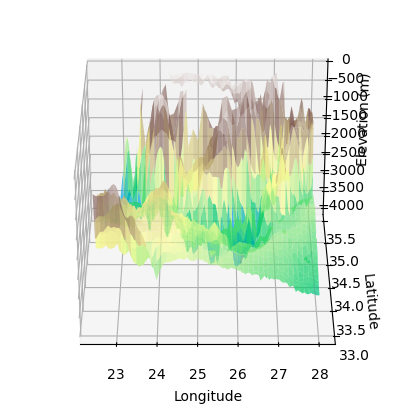

In [ ]:
#plot bathymetry
lon = bathy_iera['longitude'].values
lat = bathy_iera['latitude'].values
elev = -bathy_iera['deptho'].values
Lon, Lat = np.meshgrid(lon, lat)
fig = plt.figure(figsize=(5,5))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(Lon, Lat, elev, cmap='terrain', alpha=0.7)
ax.view_init(elev=30, azim=270)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_zlabel('Elevation (m)')
plt.show()


In [3]:
def pmk_test(ts):
    if np.isnan(ts).all():
        return np.nan, np.nan, np.nan, np.nan
    results = pymk.yue_wang_modification_test(ts)
    slope, p_value, n_ns, intercept = results.slope, results.p, results.n_ns, results.intercept
    return slope, p_value, n_ns, intercept

def std_mktrend(tseries, slope, intercept, ESS):
    x = np.arange(len(tseries))
    y_pred = (slope/365) * x + intercept
    residuals = tseries - y_pred
    std = 365*np.sqrt(np.sum(residuals**2) / (ESS - 2)) / np.sqrt(np.sum((x - np.mean(x))**2))
    return std

# Compare model/sat

In [4]:
# Mask ISOEKE IERA
# ============================================================
# 1. CONSTRUIRE LE POLYGONE IERAPETRA DEPUIS LE MASQUE EKE
# ============================================================

mask = np.load('../../../Med_Global_EKE/results/masks/2mask_IERAISO_MED.npy', allow_pickle=True)
ekem = xr.open_dataset('../../../Med_Global_EKE/processed_data/MED/ALL_SAT/NEKE_ALL_SAT_MED_C3S_vDT2021_19930101_20230607.nc')
meanekem = ekem.mean(dim='time', skipna=False)

lon = meanekem['lon'].values
lat = meanekem['lat'].values

# Résolution de la grille EKE
dlon = np.abs(np.diff(lon).mean())
dlat = np.abs(np.diff(lat).mean())
half_dlon = dlon / 2
half_dlat = dlat / 2

# ============================================================
# 2. CONSTRUIRE LES CELLULES DU MASQUE
# ============================================================

cells = []
for j, lat0 in enumerate(lat):
    for i, lon0 in enumerate(lon):

        if mask[j, i]:

            cell = box(
                lon0 - half_dlon,
                lat0 - half_dlat,
                lon0 + half_dlon,
                lat0 + half_dlat
            )
            cells.append(cell)
# Fusionner toutes les cellules
polygon_iera = unary_union(cells)

# ============================================================
# 3. PRENDRE UNIQUEMENT LA SURFACE DE UOVO
# ============================================================

uovo_surface = uovo_iera.isel(depth=0)

# ============================================================
# 4. RESOLUTION DE LA GRILLE UOVO
# ============================================================

lat_uovo = uovo_surface["latitude"].values
lon_uovo = uovo_surface["longitude"].values
dlon_uovo = np.abs(np.diff(lon_uovo).mean())
dlat_uovo = np.abs(np.diff(lat_uovo).mean())
half_dlon_uovo = dlon_uovo / 2
half_dlat_uovo = dlat_uovo / 2

# ============================================================
# 5. CONSTRUIRE LE MASQUE À LA RESOLUTION DE UOVO
# ============================================================

mask_uovo = np.zeros((len(lat_uovo), len(lon_uovo)), dtype=bool)
for j, lat0 in enumerate(lat_uovo):
    for i, lon0 in enumerate(lon_uovo):
        cell = box(
            lon0 - half_dlon_uovo,
            lat0 - half_dlat_uovo,
            lon0 + half_dlon_uovo,
            lat0 + half_dlat_uovo
        )
        if cell.intersects(polygon_iera):
            mask_uovo[j, i] = True

# ============================================================
# 6. CONVERTIR LE MASQUE EN XARRAY
# ============================================================

mask_uovo = xr.DataArray(
    mask_uovo,
    coords={"latitude": uovo_surface["latitude"], "longitude": uovo_surface["longitude"]},
    dims=("latitude", "longitude"),
    name="mask_iera")

## Vitesse totale modele

In [5]:
uovo_iera_masked = uovo_surface.where(mask_uovo)

In [6]:
uo_surf = uovo_iera_masked.uo.sel(time=slice(None, '2023-06-07'))
vo_surf = uovo_iera_masked.vo.sel(time=slice(None, '2023-06-07'))
uoa_surf = uo_surf - uo_surf.mean(dim='time')
voa_surf = vo_surf - vo_surf.mean(dim='time')
eke_surf_iera = 0.5 * (uoa_surf**2 + voa_surf**2)*10000

uo_surf = uovo_alb.uo[:,0,:,:].sel(time=slice(None, '2023-06-07'))
vo_surf = uovo_alb.vo[:,0,:,:].sel(time=slice(None, '2023-06-07'))
uoa_surf = uo_surf - uo_surf.mean(dim='time')
voa_surf = vo_surf - vo_surf.mean(dim='time')
eke_surf_alb = 0.5 * (uoa_surf**2 + voa_surf**2)*10000


area = utils.get_area_haversine(eke_surf_iera['latitude'], eke_surf_iera['longitude'])
da_area = xr.Dataset(coords={'latitude': eke_surf_iera.latitude, 'longitude': eke_surf_iera.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(eke_surf_iera.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekesurf_iera = (eke_surf_iera * area_rat).sum(['latitude', 'longitude']).compute()

area = utils.get_area_haversine(eke_surf_alb['latitude'], eke_surf_alb['longitude'])
da_area = xr.Dataset(coords={'latitude': eke_surf_alb.latitude, 'longitude': eke_surf_alb.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(eke_surf_alb.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekesurf_alb = (eke_surf_alb * area_rat).sum(['latitude', 'longitude']).compute()


In [7]:
sliera, piera, nnsiera, interiera = pmk_test(ds_meanekesurf_iera)*np.array((365,1,1,1))
incertiera = std_mktrend(ds_meanekesurf_iera, sliera, interiera, len(ds_meanekesurf_iera)/nnsiera)

slalb, palb, nnsalb, interalb = pmk_test(ds_meanekesurf_alb)*np.array((365,1,1,1))
incertalb = std_mktrend(ds_meanekesurf_alb, slalb, interalb, len(ds_meanekesurf_alb)/nnsalb)

In [8]:
# Satellites
ekem = xr.open_dataset('../../../Med_Global_EKE/processed_data/MED/ALL_SAT/NEKE_ALL_SAT_MED_C3S_vDT2021_19930101_20230607.nc')
ekea = xr.open_dataset('../../../Med_Global_EKE/processed_data/GLO/ALL_SAT/NEKE_ALL_SAT_GLO_C3S_vDT2021_19930101_20230607.nc')
eket = xr.open_dataset('../../../Med_Global_EKE/processed_data/GLO/TWO_SAT/NEKE_TWO_SAT_GLO_C3S_vDT2021_19930101_20230607.nc')
#
maskalbm = np.load('../../../Med_Global_EKE/results/masks/2mask_ALB_MED.npy', allow_pickle=True)
maskalbg = np.load('../../../Med_Global_EKE/results/masks/2mask_ALB_GLO.npy', allow_pickle=True)
ekem_alb = ekem.where(maskalbm)
ekea_alb = ekea.where(maskalbg)
eket_alb = eket.where(maskalbg)
maskierabm = np.load('../../../Med_Global_EKE/results/masks/2mask_IERAISO_MED.npy', allow_pickle=True)
maskierabg = np.load('../../../Med_Global_EKE/results/masks/2mask_IERAISO_GLO.npy', allow_pickle=True)
ekem_ierab = ekem.where(maskierabm)
ekea_ierab = ekea.where(maskierabg)
eket_ierab = eket.where(maskierabg)
#
area = utils.get_area_haversine(ekem_alb['lat'], ekem_alb['lon'])
da_area = xr.Dataset(coords={'lat': ekem_alb.lat, 'lon': ekem_alb.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekem_alb.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsm_alb = (ekem_alb * area_rat).sum(['lat', 'lon']).compute()

area = utils.get_area_haversine(ekea_alb['lat'], ekea_alb['lon'])
da_area = xr.Dataset(coords={'lat': ekea_alb.lat, 'lon': ekea_alb.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekea_alb.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsa_alb = (ekea_alb * area_rat).sum(['lat', 'lon']).compute()
dst_alb = (eket_alb * area_rat).sum(['lat', 'lon']).compute()


area = utils.get_area_haversine(ekem_ierab['lat'], ekem_ierab['lon'])
da_area = xr.Dataset(coords={'lat': ekem_ierab.lat, 'lon': ekem_ierab.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekem_ierab.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsm_ierab = (ekem_ierab * area_rat).sum(['lat', 'lon']).compute()

area = utils.get_area_haversine(ekea_ierab['lat'], ekea_ierab['lon'])
da_area = xr.Dataset(coords={'lat': ekea_ierab.lat, 'lon': ekea_ierab.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekea_ierab.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsa_ierab = (ekea_ierab * area_rat).sum(['lat', 'lon']).compute()
dst_ierab = (eket_ierab * area_rat).sum(['lat', 'lon']).compute()
#
sla_alb, pa_alb, nnsa_alb, intera_alb = pmk_test(dsa_alb.EKE)*np.array((365,1,1,1))
slt_alb, pt_alb, nnst_alb, intert_alb = pmk_test(dst_alb.EKE)*np.array((365,1,1,1))
slm_alb, pm_alb, nnsm_alb, interm_alb = pmk_test(dsm_alb.EKE)*np.array((365,1,1,1))

sla_ierab, pa_ierab, nnsa_ierab, intera_ierab = pmk_test(dsa_ierab.EKE)*np.array((365,1,1,1))
slt_ierab, pt_ierab, nnst_ierab, intert_ierab = pmk_test(dst_ierab.EKE)*np.array((365,1,1,1))
slm_ierab, pm_ierab, nnsm_ierab, interm_ierab = pmk_test(dsm_ierab.EKE)*np.array((365,1,1,1))
#
lenlen = len(dsm_alb.EKE.values)
incertm_ierab = std_mktrend(dsm_ierab.EKE.values, slm_ierab, interm_ierab, lenlen/nnsm_ierab)
incertm_alb = std_mktrend(dsm_alb.EKE.values, slm_alb, interm_alb, lenlen/nnsm_alb)
incerta_ierab = std_mktrend(dsa_ierab.EKE.values, sla_ierab, intera_ierab, lenlen/nnsa_ierab)
incerta_alb = std_mktrend(dsa_alb.EKE.values, sla_alb, intera_alb, lenlen/nnsa_alb)
incertt_ierab = std_mktrend(dst_ierab.EKE.values, slt_ierab, intert_ierab, lenlen/nnst_ierab)
incertt_alb = std_mktrend(dst_alb.EKE.values, slt_alb, intert_alb, lenlen/nnst_alb)

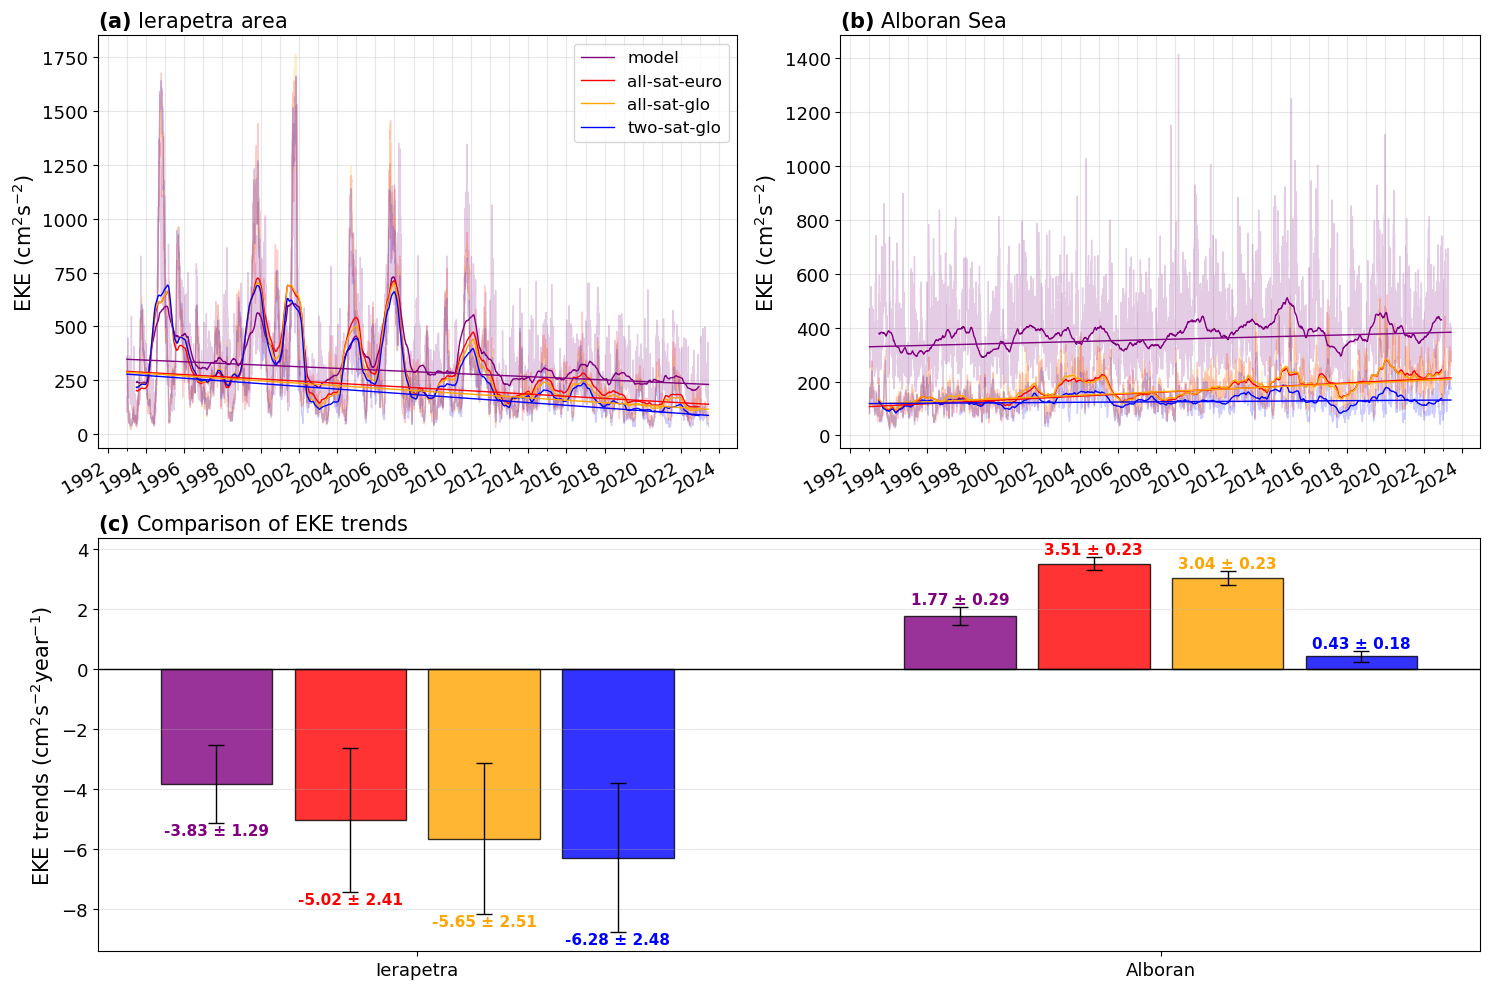

In [9]:
fig = plt.figure(figsize=(15, 10))

gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[1, 1],
    width_ratios=[1, 1],
    figure=fig
)

ax1 = fig.add_subplot(gs[0, 0])   # Ierapetra
ax2 = fig.add_subplot(gs[0, 1])   # Alboran
ax3 = fig.add_subplot(gs[1, :])   # Trends


# ============================================================
# (a) IERAPETRA
# ============================================================

ax1.plot(ds_meanekesurf_iera.time, ds_meanekesurf_iera, color='purple', lw=1, alpha=0.2)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE, color='red', lw=1, alpha=0.2)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE, color='orange', lw=1, alpha=0.2)
ax1.plot(dst_ierab.time, dst_ierab.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax1.plot(ds_meanekesurf_iera.time, ds_meanekesurf_iera.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax1.plot(dst_ierab.time, dst_ierab.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekesurf_iera.time.values - ds_meanekesurf_iera.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(ds_meanekesurf_iera.time, sliera / 365 * time_r + interiera,color='purple', linewidth=1, label='model'
        # label=(r'$\beta$ = ' + f'{sliera:.2f}' + r' $\pm$ ' + f'{incertiera:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_ierab.time.values - dsm_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsm_ierab.time, slm_ierab/365 * time_r + interm_ierab, color='red', linewidth=1, label='all-sat-euro')
time_r = ((dsa_ierab.time.values - dsa_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsa_ierab.time, sla_ierab/365 * time_r + intera_ierab, color='orange', linewidth=1, label='all-sat-glo')
time_r = ((dst_ierab.time.values - dst_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dst_ierab.time, slt_ierab/365 * time_r + intert_ierab, color='blue', linewidth=1, label='two-sat-glo')

ax1.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)
ax1.set_title(r'$\bf{(a)}$ Ierapetra area', fontsize=15, loc='left')
ax1.legend(fontsize=12, loc='upper right')
ax1.grid(True, which='both', axis='both', alpha=0.3)
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right')

# ============================================================
# (b) ALBORAN
# ============================================================

ax2.plot(ds_meanekesurf_alb.time, ds_meanekesurf_alb, color='purple', lw=1, alpha=0.2)
ax2.plot(dsm_alb.time, dsm_alb.EKE, color='red', lw=1, alpha=0.2)
ax2.plot(dsa_alb.time, dsa_alb.EKE, color='orange', lw=1, alpha=0.2)
ax2.plot(dst_alb.time, dst_alb.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax2.plot(ds_meanekesurf_alb.time, ds_meanekesurf_alb.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax2.plot(dsm_alb.time, dsm_alb.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax2.plot(dsa_alb.time, dsa_alb.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax2.plot(dst_alb.time, dst_alb.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekesurf_alb.time.values - ds_meanekesurf_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(ds_meanekesurf_alb.time, slalb / 365 * time_r + interalb, color='purple', linewidth=1,
        # label=(r'$\beta$ = ' + f'{slalb:.2f}' + r' $\pm$ ' + f'{incertalb:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_alb.time.values - dsm_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsm_alb.time, slm_alb/365 * time_r + interm_alb, color='red', linewidth=1)
time_r = ((dsa_alb.time.values - dsa_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsa_alb.time, sla_alb/365 * time_r + intera_alb, color='orange', linewidth=1)
time_r = ((dst_alb.time.values - dst_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dst_alb.time, slt_alb/365 * time_r + intert_alb, color='blue', linewidth=1)

ax2.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)
ax2.set_title(r'$\bf{(b)}$ Alboran Sea', fontsize=15, loc='left')
# ax2.legend(fontsize=12, loc='upper left')
ax2.grid(True, which='both', axis='both', alpha=0.3)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_minor_locator(mdates.YearLocator(1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right')

# ============================================================
# (c) COMPARAISON DES TENDANCES
# ============================================================

regions = ['Ierapetra', 'Alboran']

slopes_model = [sliera, slalb]
slopes_m = [slm_ierab, slm_alb]
slopes_a = [sla_ierab, sla_alb]
slopes_t = [slt_ierab, slt_alb]

errors_model = [incertiera, incertalb]
errors_m = [incertm_ierab, incertm_alb]
errors_a = [incerta_ierab, incerta_alb]
errors_t = [incertt_ierab, incertt_alb]

pvalues_model = [piera, palb]
pvalues_m = [pm_ierab, pm_alb]
pvalues_a = [pa_ierab, pa_alb]
pvalues_t = [pt_ierab, pt_alb]

xbar = np.arange(len(regions))
offset = 0.18
widthbar = 0.15

color_model = 'purple'
color_m = 'red'
color_a = 'orange'
color_t = 'blue'

all_slopes = [slopes_model, slopes_m, slopes_a, slopes_t]
all_errors = [errors_model, errors_m, errors_a, errors_t]
all_pvalues = [pvalues_model, pvalues_m, pvalues_a, pvalues_t]
all_colors = [color_model, color_m, color_a, color_t]
all_offsets = [-1.5 * offset, -0.5 * offset, 0.5 * offset, 1.5 * offset]

ax3.axhline(0, color='black', linewidth=1)
ax3.set_xticks(xbar)
ax3.set_xticklabels(regions, fontsize=15)
ax3.set_ylabel('EKE trends (cm$^2$s$^{-2}$year$^{-1}$)', fontsize=15)
ax3.set_title(r'$\bf{(c)}$ Comparison of EKE trends', fontsize=15, loc='left')
ax3.grid(True, axis='y', alpha=0.3)
for slopes, errors, pvalues, color, off in zip(all_slopes, all_errors, all_pvalues, all_colors, all_offsets):
    for i, (slope, error, pvalue) in enumerate(zip(slopes, errors, pvalues)):
        if pvalue > 0.05:
                    hatch = '//'
                    fontweight = 'normal'
                    fontstyle = 'italic'
        else:
                    hatch = None
                    fontweight = 'bold'
                    fontstyle = 'normal'
        ax3.bar(xbar[i] + off, slope, widthbar, color=color, alpha=0.8, edgecolor='black', hatch=hatch)
        ax3.errorbar(xbar[i] + off, slope, yerr=error, fmt='none', ecolor='black', elinewidth=1, capsize=6)
        if slope >= 0:
            y = slope + error
            va = 'bottom'
        else:
            y = slope - error
            va = 'top'
        ax3.text(xbar[i] + off, y, f'{slope:.2f} ± {error:.2f}',
            ha='center', va=va, fontsize=11, color=color, fontweight=fontweight, fontstyle=fontstyle)
# ax3.legend(fontsize=12, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.02))

# ============================================================
# STYLE
# ============================================================

for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=13)
plt.tight_layout()

plt.show()

In [10]:
sl_alb_mod = np.load('../../results/model_alb_slpintns.npy', allow_pickle=True)
sl_alb_mod = sl_alb_mod.item()

sl_iera_mod = np.load('../../results/model_iera_slpintns.npy', allow_pickle=True)
sl_iera_mod = sl_iera_mod.item()

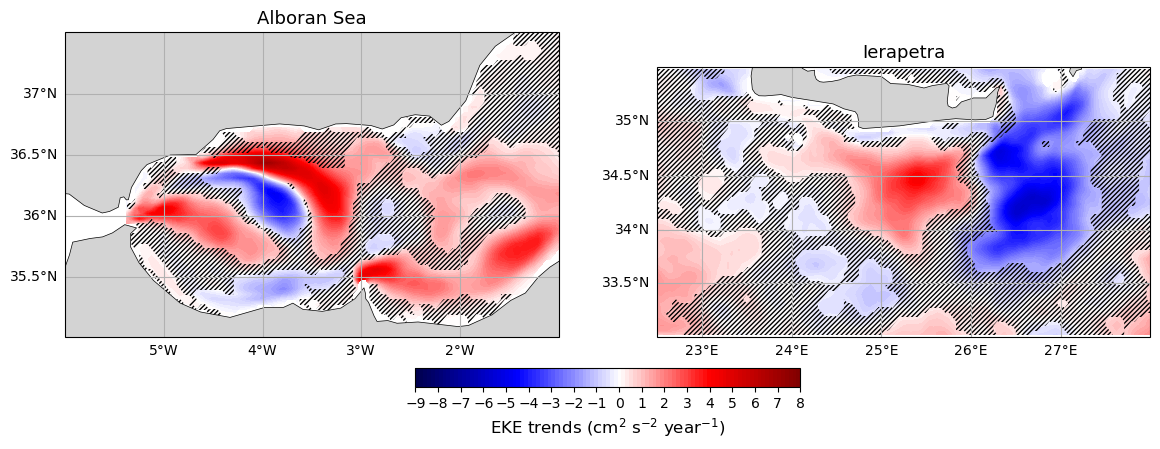

In [11]:
fig = plt.figure(figsize=(14, 5))
ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.Mercator())
ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.Mercator())

# Alboran
lon_min_alb = -6
lon_max_alb = -1
lat_min_alb = 35
lat_max_alb = 37.5

# Ierapetra
lon_min_iera = 22.5
lon_max_iera = 28
lat_min_iera = 33
lat_max_iera = 35.5

ax1.set_extent([lon_min_alb, lon_max_alb, lat_min_alb, lat_max_alb], crs=ccrs.PlateCarree())
ax2.set_extent([lon_min_iera, lon_max_iera, lat_min_iera, lat_max_iera], crs=ccrs.PlateCarree())

for ax in [ax1, ax2]:
    gl = ax.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': 'black'}
    gl.ylabel_style = {'size': 10, 'color': 'black'}

lon_alb = uovo_alb.longitude.values
lat_alb = uovo_alb.latitude.values
lon_iera = uovo_iera.longitude.values
lat_iera = uovo_iera.latitude.values

vmin = -9
vmax = 8
norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
levels = np.linspace(vmin, vmax, 100)
contour1 = ax1.contourf(lon_alb, lat_alb, sl_alb_mod['slope'] * 365, 
                        levels=levels, cmap='seismic', norm=norm, transform=ccrs.PlateCarree())
# Significance hatching
mask_alb_mod = np.where(sl_alb_mod['pvalue'] > 0.05, 1, np.nan)
ax1.contourf(lon_alb, lat_alb, mask_alb_mod, 
             levels=[0.99, 1.01], colors='none', hatches=['///////'], transform=ccrs.PlateCarree())


contour2 = ax2.contourf(lon_iera, lat_iera, sl_iera_mod['slope'] * 365,
                        levels=levels, cmap='seismic', norm=norm, transform=ccrs.PlateCarree())
# Significance hatching
mask_iera_mod = np.where(sl_iera_mod['pvalue'] > 0.05, 1, np.nan)
ax2.contourf(lon_iera, lat_iera, mask_iera_mod, levels=[0.99, 1.01],
             colors='none', hatches=['///////'], transform=ccrs.PlateCarree())

ccrs_land = cfeature.NaturalEarthFeature('physical', 'land',
    '50m', edgecolor='black', facecolor='lightgrey', linewidth=0.5)
for ax in [ax1, ax2]:
    ax.add_feature(ccrs_land)

ax1.set_title('Alboran Sea', fontsize=13)
ax2.set_title('Ierapetra', fontsize=13)
cbar = fig.colorbar(contour1, ax=[ax1, ax2], orientation='horizontal', pad=0.08, fraction=0.05)
cbar.set_label(r'EKE trends (cm$^2$ s$^{-2}$ year$^{-1}$)', fontsize=12)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin, vmax + 1, 1))

plt.show()

## Vitesse geos modele

In [19]:
# Compute vgeo model
# ============================================================
# CONSTANTES
# ============================================================

g = 9.81                  # gravité [m s-2]
Omega = 7.292115e-5       # rotation terrestre [s-1]
R = 6371000.0             # rayon terrestre [m]


# ============================================================
# POIDS DE DIFFERENCES FINIES
# ============================================================

def fd_weights_first_derivative(offsets):
    """
    Calcule les coefficients de différences finies
    pour la première dérivée.

    Parameters
    ----------
    offsets : array-like
        Positions relatives des points par rapport
        au point où la dérivée est calculée.

    Returns
    -------
    weights : ndarray
        Poids de la différence finie.
    """

    offsets = np.asarray(offsets, dtype=float)
    n = len(offsets)

    A = np.vstack([offsets**k for k in range(n)])

    b = np.zeros(n)
    b[1] = 1.0

    weights = np.linalg.solve(A, b)

    return weights


# ============================================================
# DERIVEE AVEC GESTION DES NaN
# ============================================================

def derivative_9point_nan_safe(field, axis, h):
    """
    Première dérivée spatiale avec :

    1. stencil centré 9 points si les 9 valeurs sont valides ;
    2. sinon différence centrée 2 points si possible ;
    3. sinon différence vers la droite si le point de gauche
       est NaN ;
    4. sinon différence vers la gauche si le point de droite
       est NaN ;
    5. NaN si aucun calcul physique n'est possible.

    Parameters
    ----------
    field : ndarray
        Tableau 2D ou 3D.

    axis : int
        Axe selon lequel calculer la dérivée.

    h : float
        Pas spatial.

    Returns
    -------
    derivative : ndarray
        Première dérivée.
    """

    field = np.asarray(field, dtype=np.float64)

    n = field.shape[axis]

    if n < 9:
        raise ValueError(
            "Il faut au moins 9 points dans la dimension considérée."
        )

    # --------------------------------------------------------
    # INITIALISATION
    # --------------------------------------------------------

    derivative = np.full_like(
        field,
        np.nan,
        dtype=np.float64
    )

    # ========================================================
    # POIDS DU STENCIL 9 POINTS
    # ========================================================

    offsets = np.arange(-4, 5)

    weights = fd_weights_first_derivative(offsets)

    # ========================================================
    # DERIVEE 9 POINTS
    # ========================================================

    for i in range(4, n - 4):

        points = np.arange(i - 4, i + 5)

        # ----------------------------------------------------
        # Extraction des 9 points
        # ----------------------------------------------------

        values = np.take(
            field,
            points,
            axis=axis
        )

        # ----------------------------------------------------
        # Vérification :
        # toutes les valeurs du stencil doivent être valides
        # ----------------------------------------------------

        valid_9 = np.all(
            np.isfinite(values),
            axis=axis
        )

        # ----------------------------------------------------
        # Calcul du stencil 9 points
        # ----------------------------------------------------

        result_9 = np.zeros_like(
            np.take(field, i, axis=axis),
            dtype=np.float64
        )

        for point, weight in zip(points, weights):

            result_9 += (
                weight
                * np.take(field, point, axis=axis)
            )

        result_9 /= h

        # ----------------------------------------------------
        # Insertion uniquement lorsque les 9 points sont valides
        # ----------------------------------------------------

        sl = [slice(None)] * field.ndim
        sl[axis] = i

        derivative_i = derivative[tuple(sl)]

        derivative_i[valid_9] = result_9[valid_9]

        derivative[tuple(sl)] = derivative_i

    # ========================================================
    # FALLBACK : DIFFERENCES A 2 POINTS
    # ========================================================

    for i in range(1, n - 1):

        # ----------------------------------------------------
        # Valeur centrale
        # ----------------------------------------------------

        f0 = np.take(
            field,
            i,
            axis=axis
        )

        # ----------------------------------------------------
        # Point gauche
        # ----------------------------------------------------

        f_left = np.take(
            field,
            i - 1,
            axis=axis
        )

        # ----------------------------------------------------
        # Point droit
        # ----------------------------------------------------

        f_right = np.take(
            field,
            i + 1,
            axis=axis
        )

        # ----------------------------------------------------
        # Masques de validité
        # ----------------------------------------------------

        valid_center = np.isfinite(f0)
        valid_left = np.isfinite(f_left)
        valid_right = np.isfinite(f_right)

        # ----------------------------------------------------
        # Calcul centré
        #
        # f'(x) = [f(x+h)-f(x-h)] / 2h
        # ----------------------------------------------------

        valid_centered = (
            valid_center
            & valid_left
            & valid_right
        )

        result = np.full_like(
            f0,
            np.nan,
            dtype=np.float64
        )

        result[valid_centered] = (
            f_right[valid_centered]
            - f_left[valid_centered]
        ) / (2.0 * h)

        # ----------------------------------------------------
        # Si le point gauche est NaN :
        #
        # différence vers la droite
        #
        # f'(x) = [f(x+h)-f(x)] / h
        # ----------------------------------------------------

        valid_right_only = (
            valid_center
            & (~valid_left)
            & valid_right
        )

        result[valid_right_only] = (
            f_right[valid_right_only]
            - f0[valid_right_only]
        ) / h

        # ----------------------------------------------------
        # Si le point droit est NaN :
        #
        # différence vers la gauche
        #
        # f'(x) = [f(x)-f(x-h)] / h
        # ----------------------------------------------------

        valid_left_only = (
            valid_center
            & valid_left
            & (~valid_right)
        )

        result[valid_left_only] = (
            f0[valid_left_only]
            - f_left[valid_left_only]
        ) / h

        # ----------------------------------------------------
        # On remplace uniquement les points qui n'ont pas
        # déjà obtenu une dérivée 9 points
        # ----------------------------------------------------

        sl = [slice(None)] * field.ndim
        sl[axis] = i

        derivative_i = derivative[tuple(sl)]

        fallback = np.isnan(derivative_i)

        derivative_i[fallback] = result[fallback]

        derivative[tuple(sl)] = derivative_i

    # ========================================================
    # PREMIER POINT
    # ========================================================

    f0 = np.take(field, 0, axis=axis)
    f1 = np.take(field, 1, axis=axis)

    result = np.full_like(
        f0,
        np.nan,
        dtype=np.float64
    )

    valid = (
        np.isfinite(f0)
        & np.isfinite(f1)
    )

    # différence avant
    result[valid] = (
        f1[valid] - f0[valid]
    ) / h

    sl = [slice(None)] * field.ndim
    sl[axis] = 0

    derivative[tuple(sl)] = result

    # ========================================================
    # DERNIER POINT
    # ========================================================

    fn2 = np.take(
        field,
        n - 2,
        axis=axis
    )

    fn1 = np.take(
        field,
        n - 1,
        axis=axis
    )

    result = np.full_like(
        fn1,
        np.nan,
        dtype=np.float64
    )

    valid = (
        np.isfinite(fn1)
        & np.isfinite(fn2)
    )

    # différence arrière
    result[valid] = (
        fn1[valid] - fn2[valid]
    ) / h

    sl = [slice(None)] * field.ndim
    sl[axis] = n - 1

    derivative[tuple(sl)] = result

    return derivative


# ============================================================
# CALCUL DES VITESSES GEOSTROPHIQUES
# ============================================================

def compute_geostrophic_velocity(
    zos,
    latitude,
    longitude,
    time_chunk=200
):
    """
    Calcule les vitesses géostrophiques à partir de SSH.

    ug = -g/f * dSSH/dy
    vg =  g/f * dSSH/dx

    La dérivée utilise :
        - 9 points lorsque possible ;
        - 2 points centrés près des NaN ;
        - différence vers la droite/gauche si nécessaire.

    Parameters
    ----------
    zos : xarray.DataArray
        SSH [m], dimensions :
        (time, latitude, longitude)

    latitude : 1D array
        Latitude [degrees].

    longitude : 1D array
        Longitude [degrees].

    time_chunk : int
        Nombre de pas de temps traités simultanément.

    Returns
    -------
    ug : xarray.DataArray
        Vitesse géostrophique zonale [m/s].

    vg : xarray.DataArray
        Vitesse géostrophique méridienne [m/s].
    """

    # ========================================================
    # COORDONNEES
    # ========================================================

    lat = np.asarray(
        latitude,
        dtype=float
    )

    lon = np.asarray(
        longitude,
        dtype=float
    )

    ntime = zos.sizes["time"]
    nlat = zos.sizes["latitude"]
    nlon = zos.sizes["longitude"]

    # ========================================================
    # VERIFICATION DES DIMENSIONS
    # ========================================================

    if zos.dims != (
        "time",
        "latitude",
        "longitude"
    ):
        raise ValueError(
            f"Dimensions inattendues : {zos.dims}. "
            "Attendu : "
            "('time', 'latitude', 'longitude')"
        )

    # ========================================================
    # PAS ANGULAIRES
    # ========================================================

    dlat = np.diff(lat)
    dlon = np.diff(lon)

    dphi = np.deg2rad(
        np.median(dlat)
    )

    dlambda = np.deg2rad(
        np.median(dlon)
    )

    # ========================================================
    # CORIOLIS
    # ========================================================

    phi = np.deg2rad(lat)

    f = (
        2.0
        * Omega
        * np.sin(phi)
    )

    # shape = (latitude, 1)
    f = f[:, None]

    # ========================================================
    # PAS PHYSIQUES
    # ========================================================

    dy = R * dphi

    dx = (
        R
        * np.cos(phi)
        * dlambda
    )

    # ========================================================
    # PREALLOCATION
    # ========================================================

    ug_all = np.empty(
        (ntime, nlat, nlon),
        dtype=np.float32
    )

    vg_all = np.empty(
        (ntime, nlat, nlon),
        dtype=np.float32
    )

    # ========================================================
    # BOUCLE TEMPORELLE
    # ========================================================

    for start in range(
        0,
        ntime,
        time_chunk
    ):

        end = min(
            start + time_chunk,
            ntime
        )

        print(
            f"Calcul géostrophique : "
            f"{start} -> {end} / {ntime}"
        )

        # ----------------------------------------------------
        # CHARGEMENT DU BLOC SSH
        # ----------------------------------------------------

        ssh = zos.isel(
            time=slice(start, end)
        ).values.astype(np.float64)

        # ====================================================
        # dSSH / dLATITUDE
        # ====================================================

        dssh_dphi = derivative_9point_nan_safe(
            ssh,
            axis=1,
            h=dphi
        )

        # ====================================================
        # dSSH / dLONGITUDE
        # ====================================================

        dssh_dlambda = derivative_9point_nan_safe(
            ssh,
            axis=2,
            h=dlambda
        )

        # ====================================================
        # CONVERSION EN DERIVEES PHYSIQUES
        # ====================================================

        # dSSH / dy
        dssh_dy = (
            dssh_dphi / R
        )

        # dSSH / dx
        dssh_dx = (
            dssh_dlambda
            /
            (
                R
                * np.cos(phi)[None, :, None]
            )
        )

        # ====================================================
        # VITESSES GEOSTROPHIQUES
        # ====================================================

        # ug = -g/f * dSSH/dy
        ug = (
            -g
            / f[None, :, :]
            * dssh_dy
        )

        # vg = +g/f * dSSH/dx
        vg = (
            +g
            / f[None, :, :]
            * dssh_dx
        )

        # ====================================================
        # STOCKAGE
        # ====================================================

        ug_all[start:end] = (
            ug.astype(np.float32)
        )

        vg_all[start:end] = (
            vg.astype(np.float32)
        )

    # ========================================================
    # XARRAY
    # ========================================================

    ug = xr.DataArray(
        ug_all,
        dims=(
            "time",
            "latitude",
            "longitude"
        ),
        coords={
            "time": zos.time,
            "latitude": zos.latitude,
            "longitude": zos.longitude
        },
        name="ug"
    )

    vg = xr.DataArray(
        vg_all,
        dims=(
            "time",
            "latitude",
            "longitude"
        ),
        coords={
            "time": zos.time,
            "latitude": zos.latitude,
            "longitude": zos.longitude
        },
        name="vg"
    )

    # ========================================================
    # ATTRIBUTS
    # ========================================================

    ug.attrs["long_name"] = (
        "geostrophic zonal velocity"
    )

    ug.attrs["units"] = "m s-1"

    vg.attrs["long_name"] = (
        "geostrophic meridional velocity"
    )

    vg.attrs["units"] = "m s-1"

    return ug, vg


In [20]:
# ALBORAN
zos = ssh_alb["zos"]
ug_alb, vg_alb = compute_geostrophic_velocity(zos,
    latitude=ssh_alb["latitude"].values,
    longitude=ssh_alb["longitude"].values,
    time_chunk=200)
ds_geo_alb = xr.Dataset({
    "ug": ug_alb,
    "vg": vg_alb})

# IERAPETRA
zos = ssh_iera["zos"]
ug_iera, vg_iera = compute_geostrophic_velocity(zos,
    latitude=ssh_iera["latitude"].values,
    longitude=ssh_iera["longitude"].values,
    time_chunk=200)
ds_geo_iera = xr.Dataset({
    "ug": ug_iera,
    "vg": vg_iera})

# SAUVEGARDE
ds_geo_alb.to_netcdf("../../results/006_004_medmfc_vg_alb.nc")
ds_geo_iera.to_netcdf("../../results/006_004_medmfc_vg_iera.nc")

Calcul géostrophique : 0 -> 200 / 12296
Calcul géostrophique : 200 -> 400 / 12296
Calcul géostrophique : 400 -> 600 / 12296
Calcul géostrophique : 600 -> 800 / 12296
Calcul géostrophique : 800 -> 1000 / 12296
Calcul géostrophique : 1000 -> 1200 / 12296
Calcul géostrophique : 1200 -> 1400 / 12296
Calcul géostrophique : 1400 -> 1600 / 12296
Calcul géostrophique : 1600 -> 1800 / 12296
Calcul géostrophique : 1800 -> 2000 / 12296
Calcul géostrophique : 2000 -> 2200 / 12296
Calcul géostrophique : 2200 -> 2400 / 12296
Calcul géostrophique : 2400 -> 2600 / 12296
Calcul géostrophique : 2600 -> 2800 / 12296
Calcul géostrophique : 2800 -> 3000 / 12296
Calcul géostrophique : 3000 -> 3200 / 12296
Calcul géostrophique : 3200 -> 3400 / 12296
Calcul géostrophique : 3400 -> 3600 / 12296
Calcul géostrophique : 3600 -> 3800 / 12296
Calcul géostrophique : 3800 -> 4000 / 12296
Calcul géostrophique : 4000 -> 4200 / 12296
Calcul géostrophique : 4200 -> 4400 / 12296
Calcul géostrophique : 4400 -> 4600 / 12296

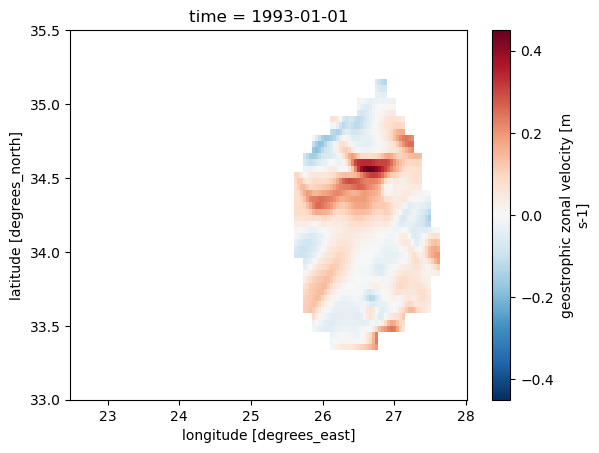

In [59]:
ds_geo_iera.ug[0,:,:].plot()

In [12]:
ds_geo_alb = xr.open_dataset('../../results/006_004_medmfc_vg_alb.nc')
ds_geo_iera = xr.open_dataset('../../results/006_004_medmfc_vg_iera.nc')

ds_geo_iera = ds_geo_iera.where(mask_uovo)

In [13]:
ug_surf = ds_geo_iera.ug.sel(time=slice(None, '2023-06-07'))
vg_surf = ds_geo_iera.vg.sel(time=slice(None, '2023-06-07'))
uga_surf = ug_surf - ug_surf.mean(dim='time')
vga_surf = vg_surf - vg_surf.mean(dim='time')
ekeg_surf_iera = 0.5 * (uga_surf**2 + vga_surf**2)*10000

ug_surf = ds_geo_alb.ug.sel(time=slice(None, '2023-06-07'))
vg_surf = ds_geo_alb.vg.sel(time=slice(None, '2023-06-07'))
uga_surf = ug_surf - ug_surf.mean(dim='time')
vga_surf = vg_surf - vg_surf.mean(dim='time')
ekeg_surf_alb = 0.5 * (uga_surf**2 + vga_surf**2)*10000


area = utils.get_area_haversine(ekeg_surf_iera['latitude'], ekeg_surf_iera['longitude'])
da_area = xr.Dataset(coords={'latitude': ekeg_surf_iera.latitude, 'longitude': ekeg_surf_iera.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(ekeg_surf_iera.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekegsurf_iera = (ekeg_surf_iera * area_rat).sum(['latitude', 'longitude']).compute()

area = utils.get_area_haversine(ekeg_surf_alb['latitude'], ekeg_surf_alb['longitude'])
da_area = xr.Dataset(coords={'latitude': ekeg_surf_alb.latitude, 'longitude': ekeg_surf_alb.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(ekeg_surf_alb.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekegsurf_alb = (ekeg_surf_alb * area_rat).sum(['latitude', 'longitude']).compute()

In [14]:
slierag, pierag, nnsierag, interierag = pmk_test(ds_meanekegsurf_iera)*np.array((365,1,1,1))
incertierag = std_mktrend(ds_meanekegsurf_iera, slierag, interierag, len(ds_meanekegsurf_iera)/nnsierag)

slalbg, palbg, nnsalbg, interalbg = pmk_test(ds_meanekegsurf_alb)*np.array((365,1,1,1))
incertalbg = std_mktrend(ds_meanekegsurf_alb, slalbg, interalbg, len(ds_meanekegsurf_alb)/nnsalbg)

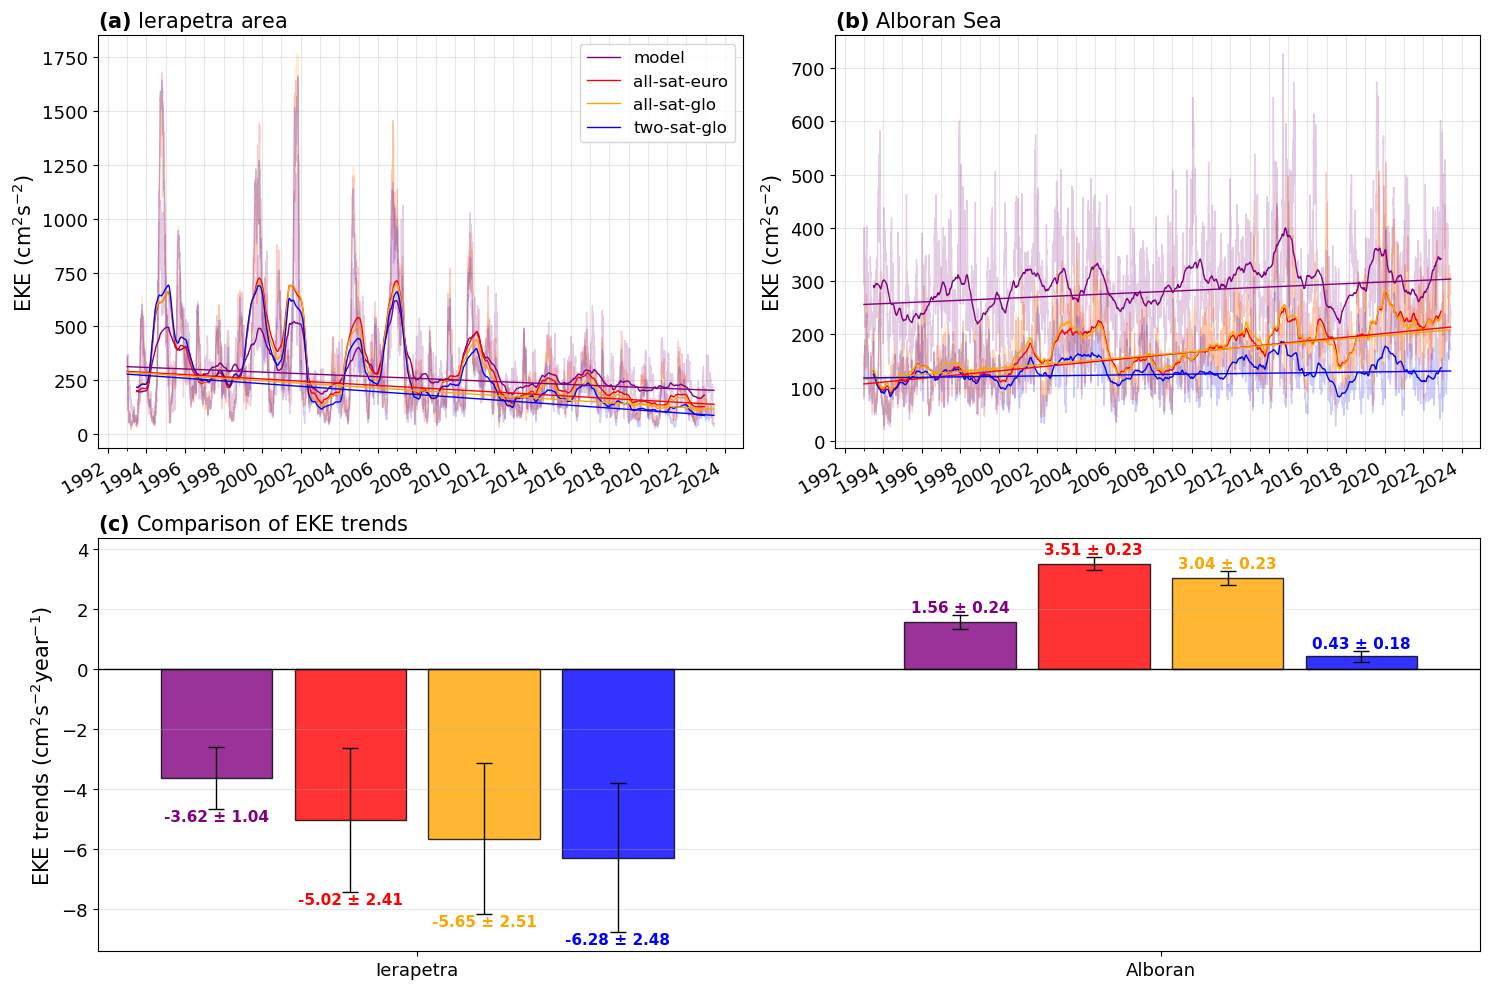

In [15]:
fig = plt.figure(figsize=(15, 10))

gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[1, 1],
    width_ratios=[1, 1],
    figure=fig)

ax1 = fig.add_subplot(gs[0, 0])   # Ierapetra
ax2 = fig.add_subplot(gs[0, 1])   # Alboran
ax3 = fig.add_subplot(gs[1, :])   # Trends

# (a) IERAPETRA
ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera, color='purple', lw=1, alpha=0.2)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE, color='red', lw=1, alpha=0.2)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE, color='orange', lw=1, alpha=0.2)
ax1.plot(dst_ierab.time, dst_ierab.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax1.plot(dst_ierab.time, dst_ierab.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekegsurf_iera.time.values - ds_meanekegsurf_iera.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(ds_meanekegsurf_iera.time, slierag / 365 * time_r + interierag,color='purple', linewidth=1, label='model'
        # label=(r'$\beta$ = ' + f'{slierag:.2f}' + r' $\pm$ ' + f'{incertierag:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_ierab.time.values - dsm_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsm_ierab.time, slm_ierab/365 * time_r + interm_ierab, color='red', linewidth=1, label='all-sat-euro')
time_r = ((dsa_ierab.time.values - dsa_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsa_ierab.time, sla_ierab/365 * time_r + intera_ierab, color='orange', linewidth=1, label='all-sat-glo')
time_r = ((dst_ierab.time.values - dst_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dst_ierab.time, slt_ierab/365 * time_r + intert_ierab, color='blue', linewidth=1, label='two-sat-glo')

ax1.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)
ax1.set_title(r'$\bf{(a)}$ Ierapetra area', fontsize=15, loc='left')
ax1.legend(fontsize=12, loc='upper right')
ax1.grid(True, which='both', axis='both', alpha=0.3)
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right')

# (b) ALBORAN
ax2.plot(ds_meanekegsurf_alb.time, ds_meanekegsurf_alb, color='purple', lw=1, alpha=0.2)
ax2.plot(dsm_alb.time, dsm_alb.EKE, color='red', lw=1, alpha=0.2)
ax2.plot(dsa_alb.time, dsa_alb.EKE, color='orange', lw=1, alpha=0.2)
ax2.plot(dst_alb.time, dst_alb.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax2.plot(ds_meanekegsurf_alb.time, ds_meanekegsurf_alb.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax2.plot(dsm_alb.time, dsm_alb.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax2.plot(dsa_alb.time, dsa_alb.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax2.plot(dst_alb.time, dst_alb.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekegsurf_alb.time.values - ds_meanekegsurf_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(ds_meanekegsurf_alb.time, slalbg / 365 * time_r + interalbg, color='purple', linewidth=1,
        # label=(r'$\beta$ = ' + f'{slalbg:.2f}' + r' $\pm$ ' + f'{incertalbg:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_alb.time.values - dsm_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsm_alb.time, slm_alb/365 * time_r + interm_alb, color='red', linewidth=1)
time_r = ((dsa_alb.time.values - dsa_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsa_alb.time, sla_alb/365 * time_r + intera_alb, color='orange', linewidth=1)
time_r = ((dst_alb.time.values - dst_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dst_alb.time, slt_alb/365 * time_r + intert_alb, color='blue', linewidth=1)

ax2.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)
ax2.set_title(r'$\bf{(b)}$ Alboran Sea', fontsize=15, loc='left')
# ax2.legend(fontsize=12, loc='upper left')
ax2.grid(True, which='both', axis='both', alpha=0.3)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_minor_locator(mdates.YearLocator(1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right')

# (c) COMPARAISON DES TENDANCES
regions = ['Ierapetra', 'Alboran']

slopes_model = [slierag, slalbg]
slopes_m = [slm_ierab, slm_alb]
slopes_a = [sla_ierab, sla_alb]
slopes_t = [slt_ierab, slt_alb]

errors_model = [incertierag, incertalbg]
errors_m = [incertm_ierab, incertm_alb]
errors_a = [incerta_ierab, incerta_alb]
errors_t = [incertt_ierab, incertt_alb]

pvalues_model = [pierag, palbg]
pvalues_m = [pm_ierab, pm_alb]
pvalues_a = [pa_ierab, pa_alb]
pvalues_t = [pt_ierab, pt_alb]

xbar = np.arange(len(regions))
offset = 0.18
widthbar = 0.15

color_model = 'purple'
color_m = 'red'
color_a = 'orange'
color_t = 'blue'

all_slopes = [slopes_model, slopes_m, slopes_a, slopes_t]
all_errors = [errors_model, errors_m, errors_a, errors_t]
all_pvalues = [pvalues_model, pvalues_m, pvalues_a, pvalues_t]
all_colors = [color_model, color_m, color_a, color_t]
all_offsets = [-1.5 * offset, -0.5 * offset, 0.5 * offset, 1.5 * offset]

ax3.axhline(0, color='black', linewidth=1)
ax3.set_xticks(xbar)
ax3.set_xticklabels(regions, fontsize=15)
ax3.set_ylabel('EKE trends (cm$^2$s$^{-2}$year$^{-1}$)', fontsize=15)
ax3.set_title(r'$\bf{(c)}$ Comparison of EKE trends', fontsize=15, loc='left')
ax3.grid(True, axis='y', alpha=0.3)

for slopes, errors, pvalues, color, off in zip(all_slopes, all_errors, all_pvalues, all_colors, all_offsets):
    for i, (slope, error, pvalue) in enumerate(zip(slopes, errors, pvalues)):
        if pvalue > 0.05:
                    hatch = '//'
                    fontweight = 'normal'
                    fontstyle = 'italic'
        else:
                    hatch = None
                    fontweight = 'bold'
                    fontstyle = 'normal'
        ax3.bar(xbar[i] + off, slope, widthbar, color=color, alpha=0.8, edgecolor='black', hatch=hatch)
        ax3.errorbar(xbar[i] + off, slope, yerr=error, fmt='none', ecolor='black', elinewidth=1, capsize=6)
        if slope >= 0:
            y = slope + error
            va = 'bottom'
        else:
            y = slope - error
            va = 'top'
        ax3.text(xbar[i] + off, y, f'{slope:.2f} ± {error:.2f}',
            ha='center', va=va, fontsize=11, color=color, fontweight=fontweight, fontstyle=fontstyle)
# ax3.legend(fontsize=12, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.02))


for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=13)
plt.tight_layout()

plt.show()

In [16]:
sl_alb_modg = np.load('../../results/model_albvg_slpintns.npy', allow_pickle=True)
sl_alb_modg = sl_alb_modg.item()

sl_iera_modg = np.load('../../results/model_ieravg_slpintns.npy', allow_pickle=True)
sl_iera_modg = sl_iera_modg.item()

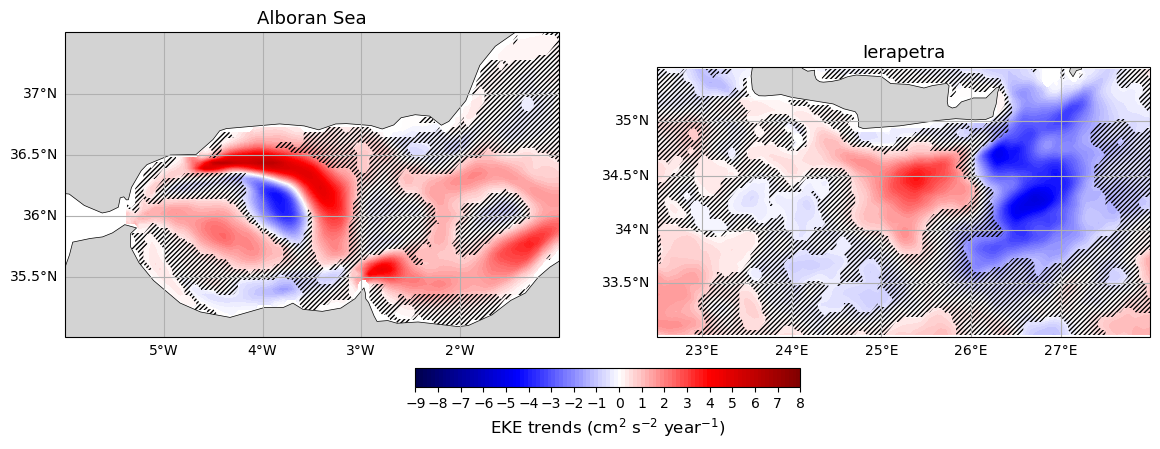

In [17]:
fig = plt.figure(figsize=(14, 5))

ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.Mercator())
ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.Mercator())

# Alboran
lon_min_alb = -6
lon_max_alb = -1
lat_min_alb = 35
lat_max_alb = 37.5

# Ierapetra
lon_min_iera = 22.5
lon_max_iera = 28
lat_min_iera = 33
lat_max_iera = 35.5

ax1.set_extent([lon_min_alb, lon_max_alb, lat_min_alb, lat_max_alb], crs=ccrs.PlateCarree())
ax2.set_extent([lon_min_iera, lon_max_iera, lat_min_iera, lat_max_iera], crs=ccrs.PlateCarree())

for ax in [ax1, ax2]:
    gl = ax.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': 'black'}
    gl.ylabel_style = {'size': 10, 'color': 'black'}

lon_alb = uovo_alb.longitude.values
lat_alb = uovo_alb.latitude.values
lon_iera = uovo_iera.longitude.values
lat_iera = uovo_iera.latitude.values

vmin = -9
vmax = 8
norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
levels = np.linspace(vmin, vmax, 100)

contour1 = ax1.contourf(lon_alb, lat_alb, sl_alb_modg['slope'] * 365, 
                        levels=levels, cmap='seismic', norm=norm, transform=ccrs.PlateCarree())
# Significance hatching
mask_alb_mod = np.where(sl_alb_modg['pvalue'] > 0.05, 1, np.nan)
ax1.contourf(lon_alb, lat_alb, mask_alb_mod, 
             levels=[0.99, 1.01], colors='none', hatches=['///////'], transform=ccrs.PlateCarree())

contour2 = ax2.contourf(lon_iera, lat_iera, sl_iera_modg['slope'] * 365,
                        levels=levels, cmap='seismic', norm=norm, transform=ccrs.PlateCarree())
# Significance hatching
mask_iera_mod = np.where(sl_iera_modg['pvalue'] > 0.05, 1, np.nan)
ax2.contourf(lon_iera, lat_iera, mask_iera_mod, levels=[0.99, 1.01],
             colors='none', hatches=['///////'], transform=ccrs.PlateCarree())

ccrs_land = cfeature.NaturalEarthFeature('physical', 'land',
    '50m', edgecolor='black', facecolor='lightgrey', linewidth=0.5)
for ax in [ax1, ax2]:
    ax.add_feature(ccrs_land)

ax1.set_title('Alboran Sea', fontsize=13)
ax2.set_title('Ierapetra', fontsize=13)
cbar = fig.colorbar(contour1, ax=[ax1, ax2], orientation='horizontal', pad=0.08, fraction=0.05)
cbar.set_label(r'EKE trends (cm$^2$ s$^{-2}$ year$^{-1}$)', fontsize=12)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin, vmax + 1, 1))

plt.show()

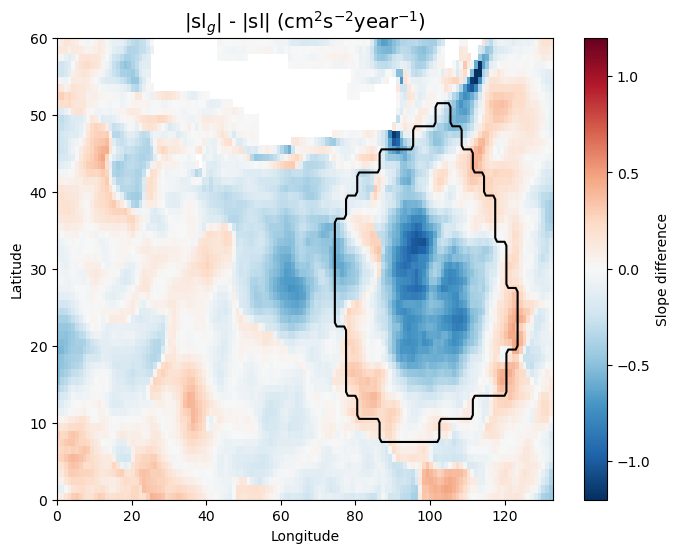

In [18]:
#Slope difference
plt.figure(figsize=(8, 6))

im = plt.pcolor(np.abs(sl_iera_modg['slope']*365) - np.abs(sl_iera_mod['slope']*365), cmap='RdBu_r', vmin=-1.2, vmax=1.2)

plt.colorbar(im, label='Slope difference')
plt.contour(mask_uovo, levels=[0.5], colors='black', linewidths=1.5)
plt.title(r'|sl$_g$| - |sl| (cm$^2$s$^{-2}$year$^{-1}$)', fontsize=14)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

## Tests 1994

In [22]:
ssh_sat = xr.open_dataset('/media/hargous/MyPassport/Med_Global_EKE/data/med_allsat_L4_008_068/vDT2021/1994/dt_med_allsat_phy_l4_1994.nc')

In [23]:
# Moyenne climatologique 1993-2012
zos_mean_932012 = ssh_iera.zos.sel(
    time=slice("1993-01-01", "2012-12-31")
).mean(dim="time")

# Anomalie de SSH
zos_anom = ssh_iera.zos - zos_mean_932012

# Moyenne de l'anomalie sur 2015
zos_anom_1994 = zos_anom.sel(
    time=slice("1994-07-01", "1994-12-31")
).mean(dim="time")

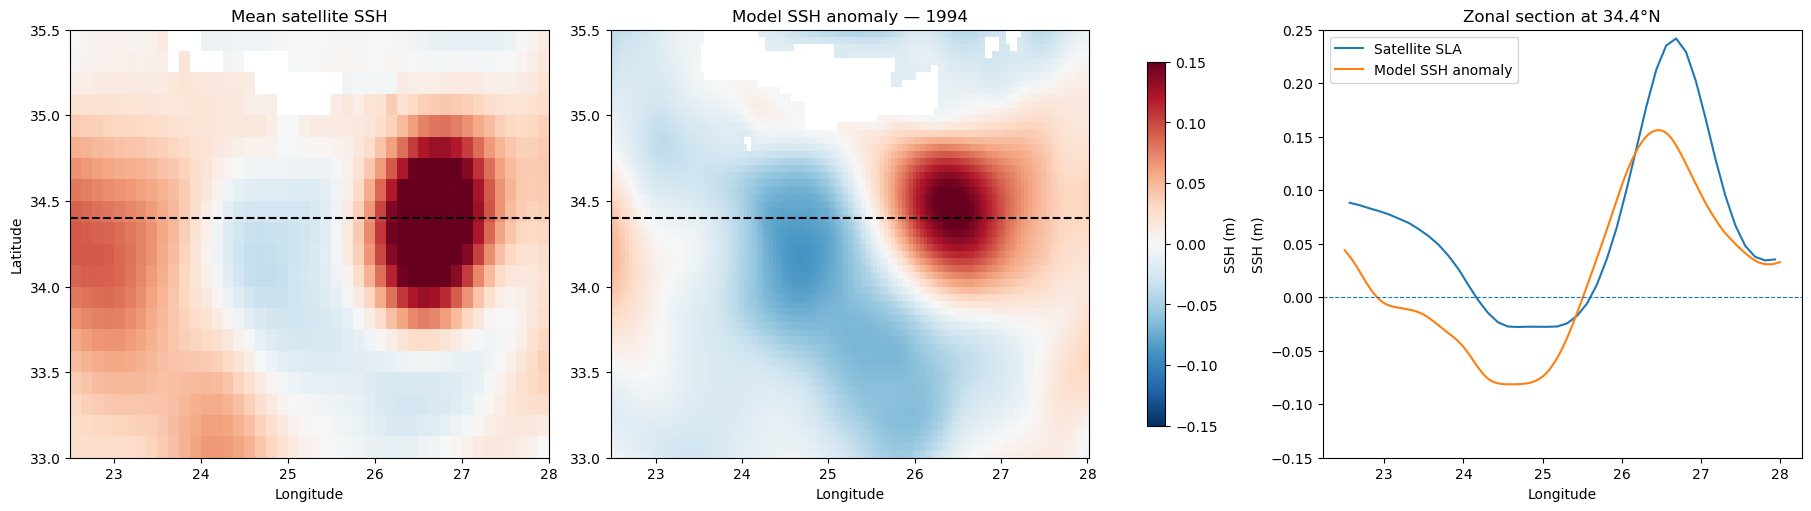

In [24]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    constrained_layout=True
)

ssh_mean = ssh_sat.sla.sel(time=slice("1994-07-01", "1994-12-31")).mean(dim="time").sel(longitude=slice(22.5, 28), latitude=slice(33, 35.5))
im1 = ssh_mean.plot(ax=axes[0], vmin=-0.15, vmax=0.15, cmap="RdBu_r", add_colorbar=False)
axes[0].axhline(34.4, color="black", linestyle="--", linewidth=1.5)
axes[0].set_title("Mean satellite SSH")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

im2 = zos_anom_1994.plot(ax=axes[1], vmin=-0.15, vmax=0.15, cmap="RdBu_r", add_colorbar=False)
axes[1].axhline(34.4, color="black", linestyle="--", linewidth=1.5)
axes[1].set_title("Model SSH anomaly — 1994")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("")

# Satellite
sla_section = ssh_sat.sla.sel(time=slice("1994-07-01", "1994-12-31")).mean(dim="time").sel(
    latitude=34.4,method="nearest"
).sel(longitude=slice(22.5, 28))

# Modèle
zos_section = zos_anom_1994.sel(
    latitude=34.4, method="nearest"
).sel(longitude=slice(22.5, 28))

axes[2].plot(sla_section.longitude, sla_section, label="Satellite SLA")
axes[2].plot(zos_section.longitude, zos_section, label="Model SSH anomaly")
axes[2].axhline(0, linestyle="--", linewidth=0.8)
axes[2].set_ylim(-0.15, 0.25)
axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("SSH (m)")
axes[2].set_title("Zonal section at 34.4°N")
axes[2].legend()

cbar = fig.colorbar(im1, ax=axes[:2], orientation="vertical", shrink=0.85, label="SSH (m)")

plt.show()

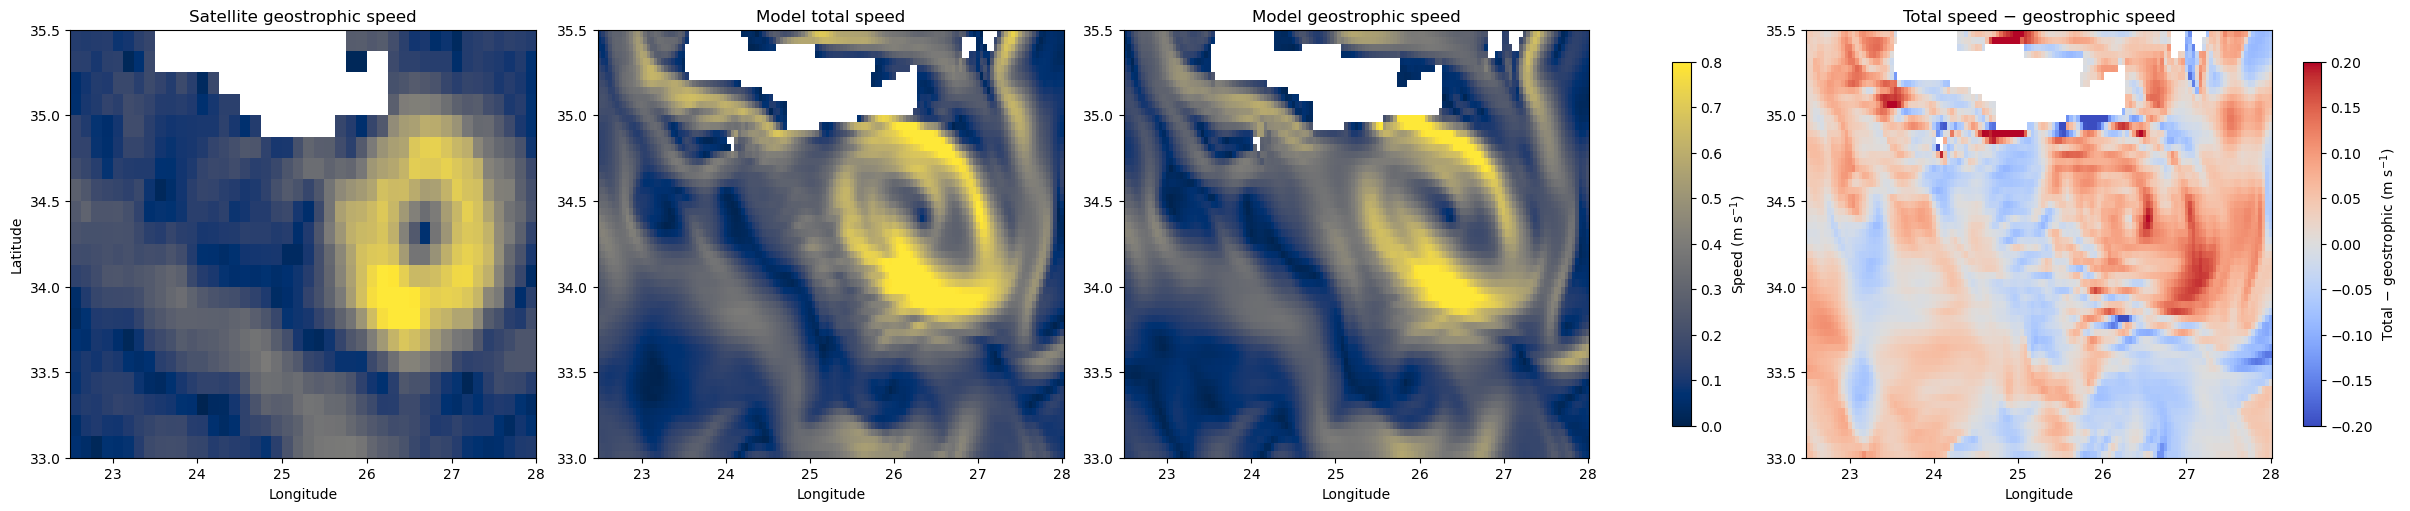

In [80]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(24, 5),
    constrained_layout=True
)

# ============================================================
# 1. Satellite : vitesse géostrophique
# ============================================================

ugos_iera_1994 = ssh_sat.ugos.sel(
    time=slice("1994-07-01", "1994-12-31"),
    longitude=slice(22.5, 28),
    latitude=slice(33, 35.5)
).sel(time="1994-10-01", method="nearest")

vgos_iera_1994 = ssh_sat.vgos.sel(
    time=slice("1994-07-01", "1994-12-31"),
    longitude=slice(22.5, 28),
    latitude=slice(33, 35.5)
).sel(time="1994-10-01", method="nearest")

speed_sat = np.sqrt(
    ugos_iera_1994**2 +
    vgos_iera_1994**2
)

speed_sat.plot(
    ax=axes[0],
    vmin=0,
    vmax=0.8,
    cmap="cividis",
    add_colorbar=False
)

axes[0].set_title("Satellite geostrophic speed")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")


# ============================================================
# 2. Modèle : vitesse totale
# ============================================================

uovo_iera_1994 = (
    uovo_iera
    .isel(depth=0)
    .sel(time=slice("1994-07-01", "1994-12-31"))
    .sel(time="1994-10-01", method="nearest")
)

speed_model_total = np.sqrt(
    uovo_iera_1994.uo**2 +
    uovo_iera_1994.vo**2
)

speed_model_total.plot(
    ax=axes[1],
    vmin=0,
    vmax=0.8,
    cmap="cividis",
    add_colorbar=False
)

axes[1].set_title("Model total speed")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("")


# ============================================================
# 3. Modèle : vitesse géostrophique
# ============================================================

ds_geo_iera_1994 = (
    ds_geo_iera
    .sel(time=slice("1994-07-01", "1994-12-31"))
    .sel(time="1994-10-01", method="nearest")
)

speed_model_geo = np.sqrt(
    ds_geo_iera_1994.ug**2 +
    ds_geo_iera_1994.vg**2
)

speed_model_geo.plot(
    ax=axes[2],
    vmin=0,
    vmax=0.8,
    cmap="cividis",
    add_colorbar=False
)

axes[2].set_title("Model geostrophic speed")
axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("")


# ============================================================
# 4. Différence : vitesse totale - vitesse géostrophique
# ============================================================

speed_difference = (
    speed_model_total - speed_model_geo
)

speed_difference.plot(
    ax=axes[3],
    vmin=-0.2,
    vmax=0.2,
    cmap="coolwarm",
    add_colorbar=False
)

axes[3].set_title(
    "Total speed − geostrophic speed"
)

axes[3].set_xlabel("Longitude")
axes[3].set_ylabel("")


# ============================================================
# Colorbar commune pour les 3 vitesses
# ============================================================

cbar_speed = fig.colorbar(
    axes[0].collections[0],
    ax=axes[:3],
    label="Speed (m s$^{-1}$)",
    shrink=0.85
)


# ============================================================
# Colorbar pour la différence
# ============================================================

cbar_diff = fig.colorbar(
    axes[3].collections[0],
    ax=axes[3],
    label="Total − geostrophic (m s$^{-1}$)",
    shrink=0.85
)

plt.show()

In [101]:
ssh_sat = ssh_sat.sel(longitude=slice(-6, 37), latitude=slice(30, 47))

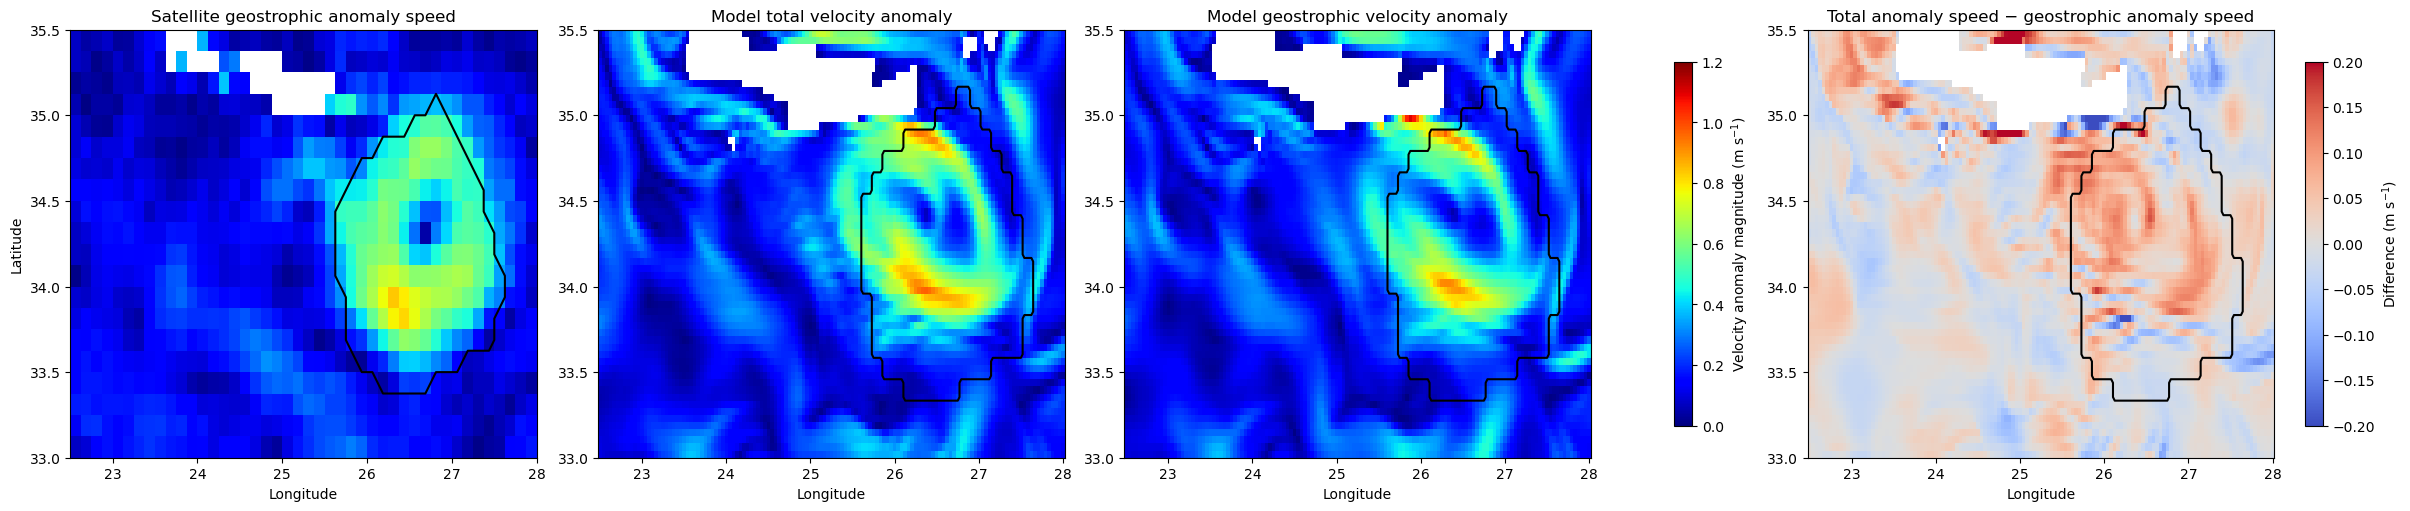

In [104]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(24, 5),
    constrained_layout=True
)

# ============================================================
# DATE D'ANALYSE
# ============================================================

date = "1994-10-01"


# ============================================================
# PERIODE DE REFERENCE MODELE
# ============================================================

clim_start = "1993-01-01"
clim_end   = "2012-12-31"


# ============================================================
# 1. SATELLITE : VITESSE GEOSTROPHIQUE ANOMALE
# ============================================================

ugosa_iera = ssh_sat.ugosa.sel(
    time=slice("1994-07-01", "1994-12-31"),
    longitude=slice(22.5, 28),
    latitude=slice(33, 35.5)
).sel(
    time=date,
    method="nearest"
)

vgosa_iera = ssh_sat.vgosa.sel(
    time=slice("1994-07-01", "1994-12-31"),
    longitude=slice(22.5, 28),
    latitude=slice(33, 35.5)
).sel(
    time=date,
    method="nearest"
)

# vitesse à partir des anomalies de composantes
speed_sat_anom = np.sqrt(
    ugosa_iera**2 +
    vgosa_iera**2
)

speed_sat_anom.plot(
    ax=axes[0],
    vmin=0,
    vmax=1.2,
    cmap="jet",
    add_colorbar=False
)
axes[0].contour(
    ssh_sat.longitude,
    ssh_sat.latitude,
    mask,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)
axes[0].set_title(
    "Satellite geostrophic anomaly speed"
)

axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")


# ============================================================
# 2. MODELE : ANOMALIE DE VITESSE TOTALE
# ============================================================

# ------------------------------------------------------------
# Climatologie 1993-2012
# ------------------------------------------------------------

uovo_clim = (
    uovo_iera
    .isel(depth=0)
    .sel(
        time=slice(
            clim_start,
            clim_end
        )
    )
    .mean(dim="time")
)

# ------------------------------------------------------------
# Champ du 1er octobre 1994
# ------------------------------------------------------------

uovo_date = (
    uovo_iera
    .isel(depth=0)
    .sel(
        time=date,
        method="nearest"
    )
)

# ------------------------------------------------------------
# Anomalies de composantes
# ------------------------------------------------------------

uo_anom = (
    uovo_date.uo -
    uovo_clim.uo
)

vo_anom = (
    uovo_date.vo -
    uovo_clim.vo
)

# ------------------------------------------------------------
# Norme de l'anomalie de vitesse
# ------------------------------------------------------------

speed_model_total_anom = np.sqrt(
    uo_anom**2 +
    vo_anom**2
)

speed_model_total_anom.plot(
    ax=axes[1],
    vmin=0,
    vmax=1.2,
    cmap="jet",
    add_colorbar=False
)
axes[1].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)
axes[1].set_title(
    "Model total velocity anomaly"
)

axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("")


# ============================================================
# 3. MODELE : ANOMALIE DE VITESSE GEOSTROPHIQUE
# ============================================================

# ------------------------------------------------------------
# Climatologie géostrophique 1993-2012
# ------------------------------------------------------------

geo_clim = (
    ds_geo_iera
    .sel(
        time=slice(
            clim_start,
            clim_end
        )
    )
    .mean(dim="time")
)

# ------------------------------------------------------------
# Champ géostrophique du 1er octobre 1994
# ------------------------------------------------------------

geo_date = (
    ds_geo_iera
    .sel(
        time=date,
        method="nearest"
    )
)

# ------------------------------------------------------------
# Anomalies des composantes géostrophiques
# ------------------------------------------------------------

ug_anom = (
    geo_date.ug -
    geo_clim.ug
)

vg_anom = (
    geo_date.vg -
    geo_clim.vg
)

# ------------------------------------------------------------
# Norme de l'anomalie géostrophique
# ------------------------------------------------------------

speed_model_geo_anom = np.sqrt(
    ug_anom**2 +
    vg_anom**2
)

speed_model_geo_anom.plot(
    ax=axes[2],
    vmin=0,
    vmax=1.2,
    cmap="jet",
    add_colorbar=False
)
axes[2].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)
axes[2].set_title(
    "Model geostrophic velocity anomaly"
)

axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("")


# ============================================================
# 4. DIFFERENCE ENTRE ANOMALIE TOTALE ET GEOSTROPHIQUE
# ============================================================

speed_difference_anom = (
    speed_model_total_anom -
    speed_model_geo_anom
)

speed_difference_anom.plot(
    ax=axes[3],
    vmin=-0.2,
    vmax=0.2,
    cmap="coolwarm",
    add_colorbar=False
)
axes[3].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)
axes[3].set_title(
    "Total anomaly speed − geostrophic anomaly speed"
)

axes[3].set_xlabel("Longitude")
axes[3].set_ylabel("")


# ============================================================
# COLORBAR : ANOMALIES DE VITESSE
# ============================================================

cbar_speed = fig.colorbar(
    axes[0].collections[0],
    ax=axes[:3],
    label="Velocity anomaly magnitude (m s$^{-1}$)",
    shrink=0.85
)


# ============================================================
# COLORBAR : DIFFERENCE
# ============================================================

cbar_diff = fig.colorbar(
    axes[3].collections[0],
    ax=axes[3],
    label="Difference (m s$^{-1}$)",
    shrink=0.85
)


plt.show()

In [105]:
# ============================================================
# Date
# ============================================================
date = "1994-10-01"

# ============================================================
# 1. SATELLITE
# ============================================================

sat_date = ssh_sat.sel(time=date, method="nearest")

u_sat_anom = sat_date["ugosa"]
v_sat_anom = sat_date["vgosa"]

eke_u_sat = 0.5 * u_sat_anom**2
eke_v_sat = 0.5 * v_sat_anom**2
eke_sat = eke_u_sat + eke_v_sat


# ============================================================
# 2. MODEL TOTAL
# ============================================================

model_date = (
    uovo_iera
    .isel(depth=0)
    .sel(time=date, method="nearest")
)

uovo_clim = (
    uovo_iera
    .isel(depth=0)
    .sel(time=slice("1993-01-01", "2012-12-31"))
    .mean("time")
)

uo_anom = model_date["uo"] - uovo_clim["uo"]
vo_anom = model_date["vo"] - uovo_clim["vo"]

eke_u_total = 0.5 * uo_anom**2
eke_v_total = 0.5 * vo_anom**2
eke_total = eke_u_total + eke_v_total


# ============================================================
# 3. MODEL GEOSTROPHIC
# ============================================================

geo_date = (
    ds_geo_iera
    .sel(time=date, method="nearest")
)

geo_clim = (
    ds_geo_iera
    .sel(time=slice("1993-01-01", "2012-12-31"))
    .mean("time")
)

ug_anom = geo_date["ug"] - geo_clim["ug"]
vg_anom = geo_date["vg"] - geo_clim["vg"]

eke_u_geo = 0.5 * ug_anom**2
eke_v_geo = 0.5 * vg_anom**2
eke_geo = eke_u_geo + eke_v_geo

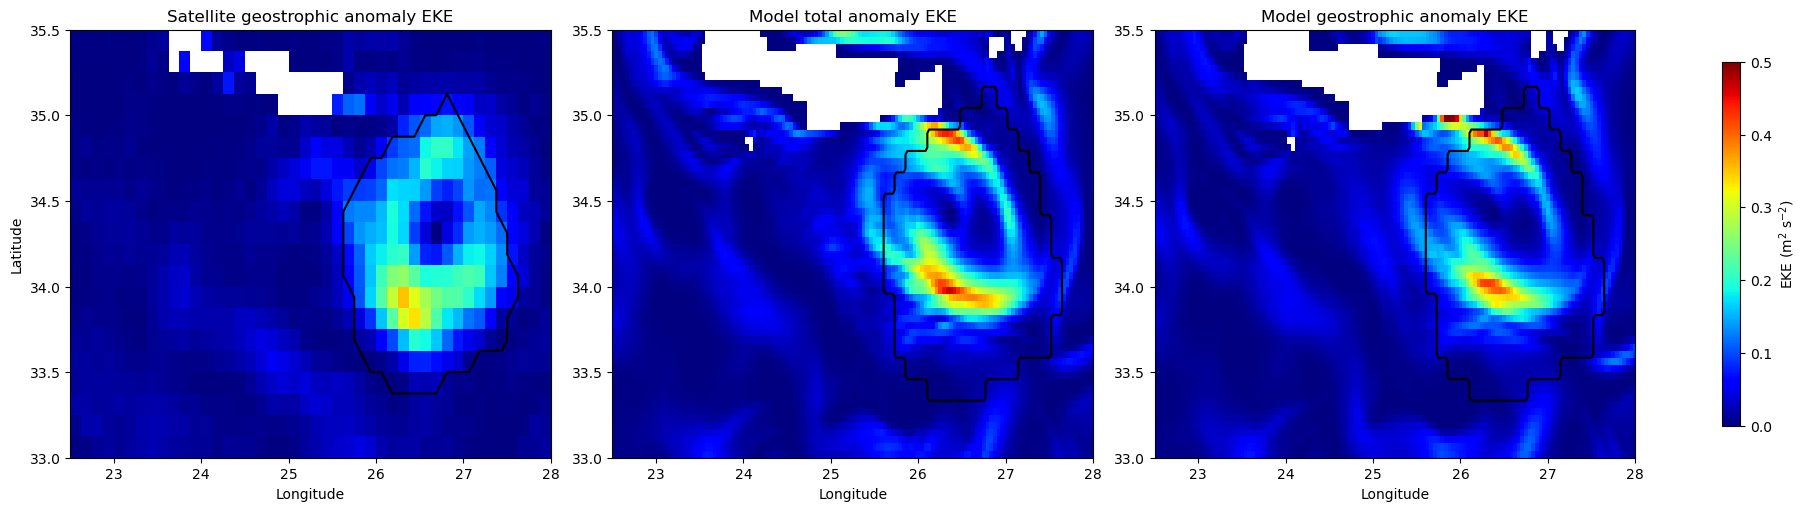

In [120]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    constrained_layout=True
)

# ============================================================
# DATE D'ANALYSE
# ============================================================

date = "1994-10-01"


# ============================================================
# PERIODE DE REFERENCE MODELE
# ============================================================

clim_start = "1993-01-01"
clim_end   = "2012-12-31"


# ============================================================
# 1. SATELLITE : EKE ANOMALE
# ============================================================

ugosa_iera = ssh_sat.ugosa.sel(
    time=slice("1994-07-01", "1994-12-31"),
    # longitude=slice(22.5, 28),
    # latitude=slice(33, 35.5)
).sel(
    time=date,
    method="nearest"
)

vgosa_iera = ssh_sat.vgosa.sel(
    time=slice("1994-07-01", "1994-12-31"),
    # longitude=slice(22.5, 28),
    # latitude=slice(33, 35.5)
).sel(
    time=date,
    method="nearest"
)

# ------------------------------------------------------------
# EKE
# ------------------------------------------------------------

eke_sat = 0.5 * (
    ugosa_iera**2 +
    vgosa_iera**2
)

eke_sat.plot(
    ax=axes[0],
    vmin=0,
    vmax=0.5,
    cmap="jet",
    add_colorbar=False
)

axes[0].contour(
    ssh_sat.longitude,
    ssh_sat.latitude,
    mask,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)

axes[0].set_title(
    "Satellite geostrophic anomaly EKE"
)

axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")


# ============================================================
# 2. MODELE : EKE ANOMALE TOTALE
# ============================================================

# ------------------------------------------------------------
# Climatologie 1993-2012
# ------------------------------------------------------------

uovo_clim = (
    uovo_iera
    .isel(depth=0)
    .sel(
        time=slice(
            clim_start,
            clim_end
        )
    )
    .mean(dim="time")
)

# ------------------------------------------------------------
# Champ du 1er octobre 1994
# ------------------------------------------------------------

uovo_date = (
    uovo_iera
    .isel(depth=0)
    .sel(
        time=date,
        method="nearest"
    )
)

# ------------------------------------------------------------
# Anomalies de composantes
# ------------------------------------------------------------

uo_anom = (
    uovo_date.uo -
    uovo_clim.uo
)

vo_anom = (
    uovo_date.vo -
    uovo_clim.vo
)

# ------------------------------------------------------------
# EKE totale
# ------------------------------------------------------------

eke_model_total = 0.5 * (
    uo_anom**2 +
    vo_anom**2
)

eke_model_total.plot(
    ax=axes[1],
    vmin=0,
    vmax=0.5,
    cmap="jet",
    add_colorbar=False
)

axes[1].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)

axes[1].set_title(
    "Model total anomaly EKE"
)

axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("")


# ============================================================
# 3. MODELE : EKE ANOMALE GEOSTROPHIQUE
# ============================================================

# ------------------------------------------------------------
# Climatologie géostrophique 1993-2012
# ------------------------------------------------------------

geo_clim = (
    ds_geo_iera
    .sel(
        time=slice(
            clim_start,
            clim_end
        )
    )
    .mean(dim="time")
)

# ------------------------------------------------------------
# Champ géostrophique du 1er octobre 1994
# ------------------------------------------------------------

geo_date = (
    ds_geo_iera
    .sel(
        time=date,
        method="nearest"
    )
)

# ------------------------------------------------------------
# Anomalies des composantes
# ------------------------------------------------------------

ug_anom = (
    geo_date.ug -
    geo_clim.ug
)

vg_anom = (
    geo_date.vg -
    geo_clim.vg
)

# ------------------------------------------------------------
# EKE géostrophique
# ------------------------------------------------------------

eke_model_geo = 0.5 * (
    ug_anom**2 +
    vg_anom**2
)

eke_model_geo.plot(
    ax=axes[2],
    vmin=0,
    vmax=0.5,
    cmap="jet",
    add_colorbar=False
)

axes[2].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)

axes[2].set_title(
    "Model geostrophic anomaly EKE"
)

axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("")


# ============================================================
# LIMITES IDENTIQUES
# ============================================================

for ax in axes:
    ax.set_xlim(22.5, 28)
    ax.set_ylim(33, 35.5)


# ============================================================
# COLORBAR UNIQUE
# ============================================================

cbar = fig.colorbar(
    axes[0].collections[0],
    ax=axes,
    label="EKE (m$^2$ s$^{-2}$)",
    shrink=0.85
)

plt.show()

# Vgeo avec 2 points

In [87]:
# ============================================================
# 1. Dérivée numérique avec 2 points
# ============================================================

def derivative_2point(field, axis, h):
    """
    Calcule une dérivée numérique avec :

    - points intérieurs :
        df/dx = (f[i+1] - f[i-1]) / (2h)

    - première frontière :
        df/dx = (f[1] - f[0]) / h

    - dernière frontière :
        df/dx = (f[-1] - f[-2]) / h

    Parameters
    ----------
    field : ndarray
        Champ sur lequel calculer la dérivée.
    axis : int
        Axe selon lequel calculer la dérivée.
    h : float
        Pas de grille.

    Returns
    -------
    derivative : ndarray
        Dérivée du champ.
    """

    field = np.asarray(field, dtype=np.float64)

    n = field.shape[axis]

    if n < 3:
        raise ValueError(
            "Il faut au moins 3 points sur l'axe considéré."
        )

    derivative = np.empty_like(field, dtype=np.float64)

    # --------------------------------------------------------
    # Points intérieurs : différence centrée
    # --------------------------------------------------------

    sl_center = [slice(None)] * field.ndim
    sl_center[axis] = slice(1, n - 1)

    sl_forward = [slice(None)] * field.ndim
    sl_forward[axis] = slice(2, n)

    sl_backward = [slice(None)] * field.ndim
    sl_backward[axis] = slice(0, n - 2)

    derivative[tuple(sl_center)] = (
        field[tuple(sl_forward)]
        - field[tuple(sl_backward)]
    ) / (2.0 * h)

    # --------------------------------------------------------
    # Premier point : différence avant
    # --------------------------------------------------------

    sl0 = [slice(None)] * field.ndim
    sl0[axis] = 0

    sl1 = [slice(None)] * field.ndim
    sl1[axis] = 1

    derivative[tuple(sl0)] = (
        field[tuple(sl1)]
        - field[tuple(sl0)]
    ) / h

    # --------------------------------------------------------
    # Dernier point : différence arrière
    # --------------------------------------------------------

    sl_last = [slice(None)] * field.ndim
    sl_last[axis] = n - 1

    sl_before = [slice(None)] * field.ndim
    sl_before[axis] = n - 2

    derivative[tuple(sl_last)] = (
        field[tuple(sl_last)]
        - field[tuple(sl_before)]
    ) / h

    return derivative


# ============================================================
# 2. Calcul des vitesses géostrophiques à partir de SSH
# ============================================================

def compute_geostrophic_velocity(
    zos,
    latitude,
    longitude,
    g=9.81,
    Omega=7.292115e-5,
    R=6371000.0,
    time_chunk=200
):
    """
    Calcule les vitesses géostrophiques à partir de la SSH.

    Équations :

        ug = -g/f * dSSH/dy

        vg =  g/f * dSSH/dx

    avec :

        dy = R dphi

        dx = R cos(phi) dlambda

        f = 2 Omega sin(phi)

    Parameters
    ----------
    zos : xarray.DataArray
        SSH avec dimensions (time, latitude, longitude).

    latitude : array
        Latitudes en degrés.

    longitude : array
        Longitudes en degrés.

    g : float
        Accélération gravitationnelle.

    Omega : float
        Vitesse de rotation de la Terre.

    R : float
        Rayon terrestre.

    time_chunk : int
        Nombre de dates traitées simultanément.

    Returns
    -------
    ug : xarray.DataArray
        Vitesse zonale géostrophique.

    vg : xarray.DataArray
        Vitesse méridienne géostrophique.
    """

    # --------------------------------------------------------
    # Vérification des dimensions
    # --------------------------------------------------------

    if zos.dims != ("time", "latitude", "longitude"):
        raise ValueError(
            f"Dimensions inattendues : {zos.dims}. "
            "Les dimensions doivent être "
            "('time', 'latitude', 'longitude')."
        )

    lat = np.asarray(latitude, dtype=np.float64)
    lon = np.asarray(longitude, dtype=np.float64)

    # --------------------------------------------------------
    # Pas de grille
    #
    # On utilise la médiane car les coordonnées sont en float32
    # et peuvent avoir de très petites différences numériques.
    # --------------------------------------------------------

    dlat = np.diff(lat)
    dlon = np.diff(lon)

    dphi = np.deg2rad(np.median(dlat))
    dlambda = np.deg2rad(np.median(dlon))

    # --------------------------------------------------------
    # Vérification que la grille est bien quasi régulière
    # --------------------------------------------------------

    if not np.allclose(
        dlat,
        np.median(dlat),
        rtol=1e-4,
        atol=1e-7
    ):
        raise ValueError(
            "La grille latitude est trop irrégulière."
        )

    if not np.allclose(
        dlon,
        np.median(dlon),
        rtol=1e-4,
        atol=1e-7
    ):
        raise ValueError(
            "La grille longitude est trop irrégulière."
        )

    # --------------------------------------------------------
    # Latitude en radians
    # --------------------------------------------------------

    phi = np.deg2rad(lat)

    # Coriolis
    f = 2.0 * Omega * np.sin(phi)

    # --------------------------------------------------------
    # Préparation des coordonnées
    # --------------------------------------------------------

    ug = np.empty(
        zos.shape,
        dtype=np.float32
    )

    vg = np.empty(
        zos.shape,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Traitement par blocs temporels
    # --------------------------------------------------------

    for i0 in range(0, zos.sizes["time"], time_chunk):

        i1 = min(
            i0 + time_chunk,
            zos.sizes["time"]
        )

        print(
            f"Calcul géostrophique : "
            f"{i0} - {i1} / {zos.sizes['time']}"
        )

        # ----------------------------------------------------
        # Lecture du bloc
        # ----------------------------------------------------

        ssh = zos.isel(
            time=slice(i0, i1)
        ).values

        ssh = np.asarray(
            ssh,
            dtype=np.float64
        )

        # ----------------------------------------------------
        # dSSH / dphi
        #
        # axe 1 = latitude
        # ----------------------------------------------------

        dssh_dphi = derivative_2point(
            ssh,
            axis=1,
            h=dphi
        )

        # ----------------------------------------------------
        # dSSH / dlambda
        #
        # axe 2 = longitude
        # ----------------------------------------------------

        dssh_dlambda = derivative_2point(
            ssh,
            axis=2,
            h=dlambda
        )

        # ----------------------------------------------------
        # Conversion en dérivées physiques
        #
        # dSSH/dy = dSSH/dphi / R
        #
        # dSSH/dx = dSSH/dlambda /
        #           (R cos(phi))
        # ----------------------------------------------------

        dssh_dy = dssh_dphi / R

        cosphi = np.cos(phi)[None, :, None]

        dssh_dx = (
            dssh_dlambda
            / (R * cosphi)
        )

        # ----------------------------------------------------
        # Vitesses géostrophiques
        #
        # ug = -g/f * dSSH/dy
        #
        # vg =  g/f * dSSH/dx
        # ----------------------------------------------------

        f_3d = f[None, :, None]

        ug_block = (
            -g
            / f_3d
            * dssh_dy
        )

        vg_block = (
            g
            / f_3d
            * dssh_dx
        )

        # ----------------------------------------------------
        # Stockage
        # ----------------------------------------------------

        ug[i0:i1, :, :] = ug_block.astype(
            np.float32
        )

        vg[i0:i1, :, :] = vg_block.astype(
            np.float32
        )

    # ========================================================
    # Création des DataArrays xarray
    # ========================================================

    ug = xr.DataArray(
        ug,
        dims=zos.dims,
        coords=zos.coords,
        name="ug"
    )

    vg = xr.DataArray(
        vg,
        dims=zos.dims,
        coords=zos.coords,
        name="vg"
    )

    # --------------------------------------------------------
    # Attributs
    # --------------------------------------------------------

    ug.attrs = {
        "long_name": "geostrophic zonal velocity",
        "units": "m s-1",
        "description": (
            "Geostrophic velocity calculated from "
            "sea surface height"
        )
    }

    vg.attrs = {
        "long_name": "geostrophic meridional velocity",
        "units": "m s-1",
        "description": (
            "Geostrophic velocity calculated from "
            "sea surface height"
        )
    }

    return ug, vg


# ============================================================
# 3. ALBORAN
# ============================================================

zos = ssh_alb["zos"]

ug_alb, vg_alb = compute_geostrophic_velocity(
    zos,
    latitude=ssh_alb["latitude"].values,
    longitude=ssh_alb["longitude"].values,
    time_chunk=200
)

ds_geo_alb = xr.Dataset(
    {
        "ug": ug_alb,
        "vg": vg_alb
    }
)


# ============================================================
# 4. IERAPETRA
# ============================================================

zos = ssh_iera["zos"]

ug_iera, vg_iera = compute_geostrophic_velocity(
    zos,
    latitude=ssh_iera["latitude"].values,
    longitude=ssh_iera["longitude"].values,
    time_chunk=200
)

ds_geo_iera = xr.Dataset(
    {
        "ug": ug_iera,
        "vg": vg_iera
    }
)

Calcul géostrophique : 0 - 200 / 12296
Calcul géostrophique : 200 - 400 / 12296
Calcul géostrophique : 400 - 600 / 12296
Calcul géostrophique : 600 - 800 / 12296
Calcul géostrophique : 800 - 1000 / 12296
Calcul géostrophique : 1000 - 1200 / 12296
Calcul géostrophique : 1200 - 1400 / 12296
Calcul géostrophique : 1400 - 1600 / 12296
Calcul géostrophique : 1600 - 1800 / 12296
Calcul géostrophique : 1800 - 2000 / 12296
Calcul géostrophique : 2000 - 2200 / 12296
Calcul géostrophique : 2200 - 2400 / 12296
Calcul géostrophique : 2400 - 2600 / 12296
Calcul géostrophique : 2600 - 2800 / 12296
Calcul géostrophique : 2800 - 3000 / 12296
Calcul géostrophique : 3000 - 3200 / 12296
Calcul géostrophique : 3200 - 3400 / 12296
Calcul géostrophique : 3400 - 3600 / 12296
Calcul géostrophique : 3600 - 3800 / 12296
Calcul géostrophique : 3800 - 4000 / 12296
Calcul géostrophique : 4000 - 4200 / 12296
Calcul géostrophique : 4200 - 4400 / 12296
Calcul géostrophique : 4400 - 4600 / 12296
Calcul géostrophique :

In [88]:
ug_surf = ds_geo_iera.ug.sel(time=slice(None, '2023-06-07'))
vg_surf = ds_geo_iera.vg.sel(time=slice(None, '2023-06-07'))
uga_surf = ug_surf - ug_surf.mean(dim='time')
vga_surf = vg_surf - vg_surf.mean(dim='time')
ekeg_surf_iera = 0.5 * (uga_surf**2 + vga_surf**2)*10000

ug_surf = ds_geo_alb.ug.sel(time=slice(None, '2023-06-07'))
vg_surf = ds_geo_alb.vg.sel(time=slice(None, '2023-06-07'))
uga_surf = ug_surf - ug_surf.mean(dim='time')
vga_surf = vg_surf - vg_surf.mean(dim='time')
ekeg_surf_alb = 0.5 * (uga_surf**2 + vga_surf**2)*10000

In [89]:
area = utils.get_area_haversine(ekeg_surf_iera['latitude'], ekeg_surf_iera['longitude'])
da_area = xr.Dataset(coords={'latitude': ekeg_surf_iera.latitude, 'longitude': ekeg_surf_iera.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(ekeg_surf_iera.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekegsurf_iera = (ekeg_surf_iera * area_rat).sum(['latitude', 'longitude']).compute()

area = utils.get_area_haversine(ekeg_surf_alb['latitude'], ekeg_surf_alb['longitude'])
da_area = xr.Dataset(coords={'latitude': ekeg_surf_alb.latitude, 'longitude': ekeg_surf_alb.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(ekeg_surf_alb.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekegsurf_alb = (ekeg_surf_alb * area_rat).sum(['latitude', 'longitude']).compute()


In [90]:
slierag, pierag, nnsierag, interierag = pmk_test(ds_meanekegsurf_iera)*np.array((365,1,1,1))
incertierag = std_mktrend(ds_meanekegsurf_iera, slierag, interierag, len(ds_meanekegsurf_iera)/nnsierag)

slalbg, palbg, nnsalbg, interalbg = pmk_test(ds_meanekegsurf_alb)*np.array((365,1,1,1))
incertalbg = std_mktrend(ds_meanekegsurf_alb, slalbg, interalbg, len(ds_meanekegsurf_alb)/nnsalbg)

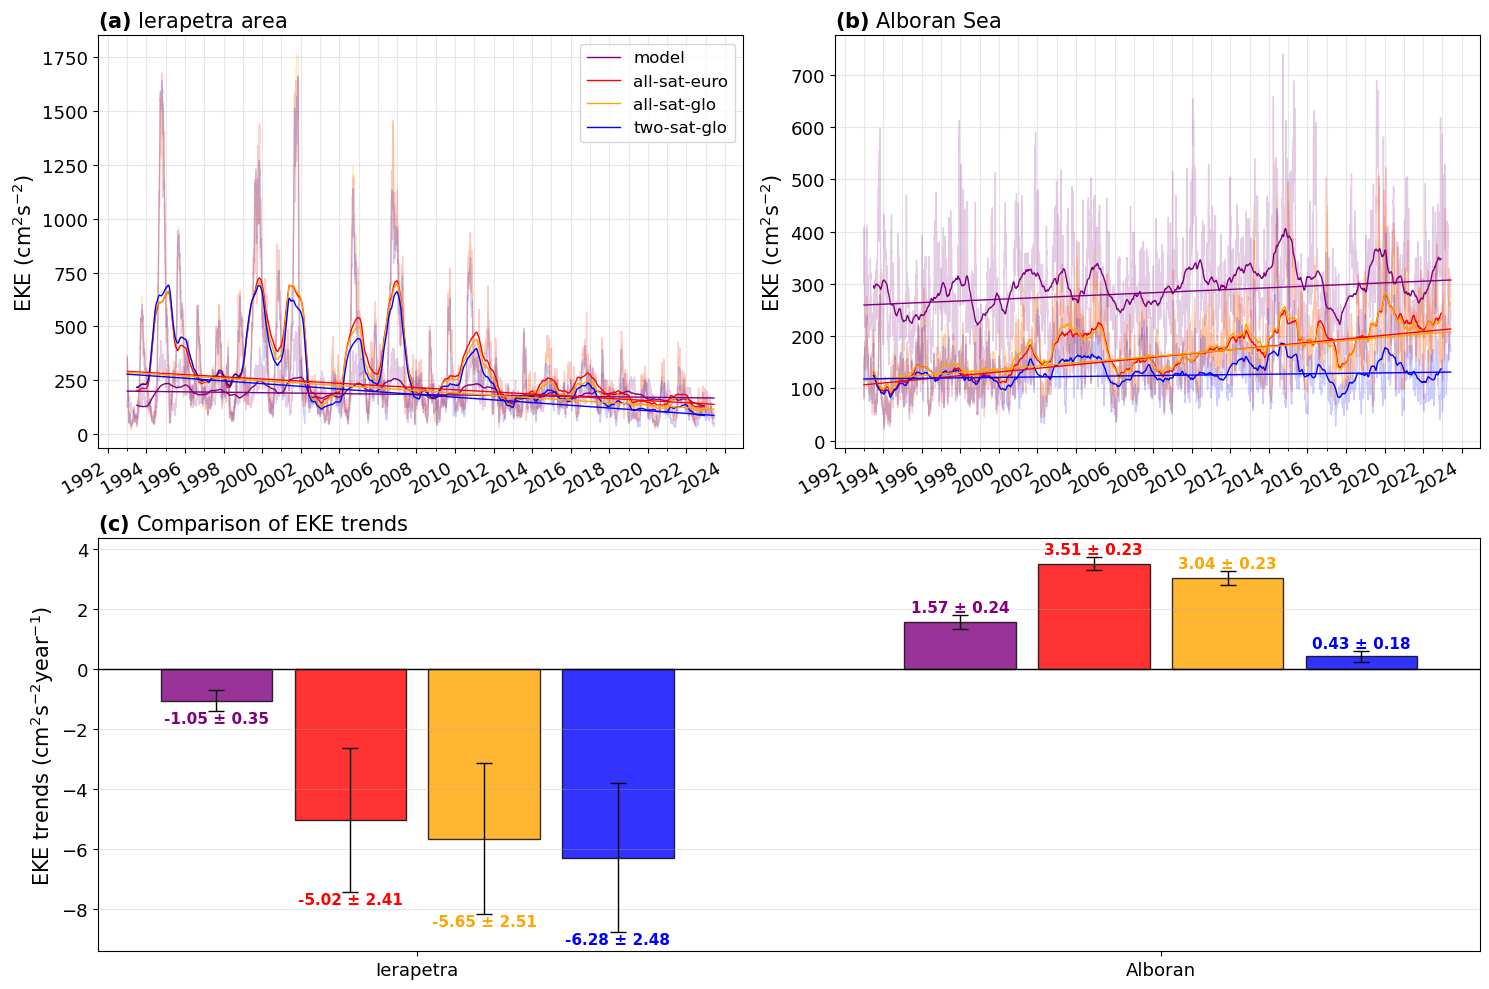

In [91]:
fig = plt.figure(figsize=(15, 10))

gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[1, 1],
    width_ratios=[1, 1],
    figure=fig
)

ax1 = fig.add_subplot(gs[0, 0])   # Ierapetra
ax2 = fig.add_subplot(gs[0, 1])   # Alboran
ax3 = fig.add_subplot(gs[1, :])   # Trends


# ============================================================
# (a) IERAPETRA
# ============================================================

ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera, color='purple', lw=1, alpha=0.2)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE, color='red', lw=1, alpha=0.2)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE, color='orange', lw=1, alpha=0.2)
ax1.plot(dst_ierab.time, dst_ierab.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax1.plot(dst_ierab.time, dst_ierab.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekegsurf_iera.time.values - ds_meanekegsurf_iera.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(ds_meanekegsurf_iera.time, slierag / 365 * time_r + interierag,color='purple', linewidth=1, label='model'
        # label=(r'$\beta$ = ' + f'{slierag:.2f}' + r' $\pm$ ' + f'{incertierag:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_ierab.time.values - dsm_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsm_ierab.time, slm_ierab/365 * time_r + interm_ierab, color='red', linewidth=1, label='all-sat-euro')
time_r = ((dsa_ierab.time.values - dsa_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsa_ierab.time, sla_ierab/365 * time_r + intera_ierab, color='orange', linewidth=1, label='all-sat-glo')
time_r = ((dst_ierab.time.values - dst_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dst_ierab.time, slt_ierab/365 * time_r + intert_ierab, color='blue', linewidth=1, label='two-sat-glo')

ax1.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)

ax1.set_title(r'$\bf{(a)}$ Ierapetra area', fontsize=15, loc='left')

ax1.legend(fontsize=12, loc='upper right')

ax1.grid(True, which='both', axis='both', alpha=0.3)

ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right')


# ============================================================
# (b) ALBORAN
# ============================================================

ax2.plot(ds_meanekegsurf_alb.time, ds_meanekegsurf_alb, color='purple', lw=1, alpha=0.2)
ax2.plot(dsm_alb.time, dsm_alb.EKE, color='red', lw=1, alpha=0.2)
ax2.plot(dsa_alb.time, dsa_alb.EKE, color='orange', lw=1, alpha=0.2)
ax2.plot(dst_alb.time, dst_alb.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax2.plot(ds_meanekegsurf_alb.time, ds_meanekegsurf_alb.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax2.plot(dsm_alb.time, dsm_alb.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax2.plot(dsa_alb.time, dsa_alb.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax2.plot(dst_alb.time, dst_alb.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekegsurf_alb.time.values - ds_meanekegsurf_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(ds_meanekegsurf_alb.time, slalbg / 365 * time_r + interalbg, color='purple', linewidth=1,
        # label=(r'$\beta$ = ' + f'{slalbg:.2f}' + r' $\pm$ ' + f'{incertalbg:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_alb.time.values - dsm_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsm_alb.time, slm_alb/365 * time_r + interm_alb, color='red', linewidth=1)
time_r = ((dsa_alb.time.values - dsa_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsa_alb.time, sla_alb/365 * time_r + intera_alb, color='orange', linewidth=1)
time_r = ((dst_alb.time.values - dst_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dst_alb.time, slt_alb/365 * time_r + intert_alb, color='blue', linewidth=1)

ax2.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)

ax2.set_title(r'$\bf{(b)}$ Alboran Sea', fontsize=15, loc='left')

# ax2.legend(fontsize=12, loc='upper left')

ax2.grid(True, which='both', axis='both', alpha=0.3)

ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_minor_locator(mdates.YearLocator(1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right')


# ============================================================
# (c) COMPARAISON DES TENDANCES
# ============================================================

regions = ['Ierapetra', 'Alboran']

slopes_model = [slierag, slalbg]
slopes_m = [slm_ierab, slm_alb]
slopes_a = [sla_ierab, sla_alb]
slopes_t = [slt_ierab, slt_alb]

errors_model = [incertierag, incertalbg]
errors_m = [incertm_ierab, incertm_alb]
errors_a = [incerta_ierab, incerta_alb]
errors_t = [incertt_ierab, incertt_alb]

pvalues_model = [pierag, palbg]
pvalues_m = [pm_ierab, pm_alb]
pvalues_a = [pa_ierab, pa_alb]
pvalues_t = [pt_ierab, pt_alb]

xbar = np.arange(len(regions))
offset = 0.18
widthbar = 0.15

color_model = 'purple'
color_m = 'red'
color_a = 'orange'
color_t = 'blue'

all_slopes = [slopes_model, slopes_m, slopes_a, slopes_t]
all_errors = [errors_model, errors_m, errors_a, errors_t]
all_pvalues = [pvalues_model, pvalues_m, pvalues_a, pvalues_t]
all_colors = [color_model, color_m, color_a, color_t]
all_offsets = [-1.5 * offset, -0.5 * offset, 0.5 * offset, 1.5 * offset]

ax3.axhline(0, color='black', linewidth=1)

ax3.set_xticks(xbar)
ax3.set_xticklabels(regions, fontsize=15)

ax3.set_ylabel('EKE trends (cm$^2$s$^{-2}$year$^{-1}$)', fontsize=15)

ax3.set_title(r'$\bf{(c)}$ Comparison of EKE trends', fontsize=15, loc='left')

ax3.grid(True, axis='y', alpha=0.3)

for slopes, errors, pvalues, color, off in zip(all_slopes, all_errors, all_pvalues, all_colors, all_offsets):
    for i, (slope, error, pvalue) in enumerate(zip(slopes, errors, pvalues)):
        if pvalue > 0.05:
                    hatch = '//'
                    fontweight = 'normal'
                    fontstyle = 'italic'
        else:
                    hatch = None
                    fontweight = 'bold'
                    fontstyle = 'normal'
        ax3.bar(xbar[i] + off, slope, widthbar, color=color, alpha=0.8, edgecolor='black', hatch=hatch)
        ax3.errorbar(xbar[i] + off, slope, yerr=error, fmt='none', ecolor='black', elinewidth=1, capsize=6)

        if slope >= 0:
            y = slope + error
            va = 'bottom'
        else:
            y = slope - error
            va = 'top'
        ax3.text(xbar[i] + off, y, f'{slope:.2f} ± {error:.2f}',
            ha='center', va=va, fontsize=11, color=color, fontweight=fontweight, fontstyle=fontstyle)

# ax3.legend(fontsize=12, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.02))

# ============================================================
# STYLE
# ============================================================

for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=13)

plt.tight_layout()

plt.show()

# Test

In [19]:
# ============================================================
# CALCUL DES TENDANCES POUR DIFFERENTES PERIODES
# ============================================================

periods = {
    '1993-2012': ("1993-01-01", "2012-12-31"),
    '2013-2023': ("2013-01-01", "2023-06-07")
}

regions_data = {
    'Ierapetra': {
        'model': ds_meanekegsurf_iera,
        'all-sat-euro': dsm_ierab.EKE,
        'all-sat-glo': dsa_ierab.EKE,
        'two-sat-glo': dst_ierab.EKE
    },
    'Alboran': {
        'model': ds_meanekegsurf_alb,
        'all-sat-euro': dsm_alb.EKE,
        'all-sat-glo': dsa_alb.EKE,
        'two-sat-glo': dst_alb.EKE
    }
}

# Dictionnaire contenant les résultats
results = {}
for region, datasets in regions_data.items():
    results[region] = {}
    for dataset_name, ds in datasets.items():
        results[region][dataset_name] = {}
        for period_name, (start, end) in periods.items():
            ds_period = ds.sel(time=slice(start, end))
            sl, p, nns, inter = (
                pmk_test(ds_period) * np.array((365, 1, 1, 1))
            )
            incert = std_mktrend(ds_period, sl, inter, len(ds_period) / nns)
            results[region][dataset_name][period_name] = {
                'slope': sl,
                'pvalue': p,
                'nns': nns,
                'intercept': inter,
                'error': incert
            }
            print(
                f"{region} | {dataset_name} | {period_name}: "
                f"slope = {sl:.3f} ± {incert:.3f}, p = {p:.4f}"
            )

Ierapetra | model | 1993-2012: slope = -0.448 ± 1.213, p = 0.6337
Ierapetra | model | 2013-2023: slope = -5.244 ± 1.331, p = 0.0001
Ierapetra | all-sat-euro | 1993-2012: slope = -1.224 ± 2.694, p = 0.4146
Ierapetra | all-sat-euro | 2013-2023: slope = -8.159 ± 1.804, p = 0.0000
Ierapetra | all-sat-glo | 1993-2012: slope = -2.878 ± 2.685, p = 0.0426
Ierapetra | all-sat-glo | 2013-2023: slope = -7.890 ± 1.513, p = 0.0000
Ierapetra | two-sat-glo | 1993-2012: slope = -3.758 ± 2.803, p = 0.0109
Ierapetra | two-sat-glo | 2013-2023: slope = -8.385 ± 1.423, p = 0.0000
Alboran | model | 1993-2012: slope = 2.501 ± 0.340, p = 0.0000
Alboran | model | 2013-2023: slope = -1.309 ± 1.790, p = 0.4193
Alboran | all-sat-euro | 1993-2012: slope = 3.436 ± 0.515, p = 0.0000
Alboran | all-sat-euro | 2013-2023: slope = 6.041 ± 1.157, p = 0.0000
Alboran | all-sat-glo | 1993-2012: slope = 3.017 ± 0.521, p = 0.0000
Alboran | all-sat-glo | 2013-2023: slope = 4.388 ± 1.325, p = 0.0002
Alboran | two-sat-glo | 1993-

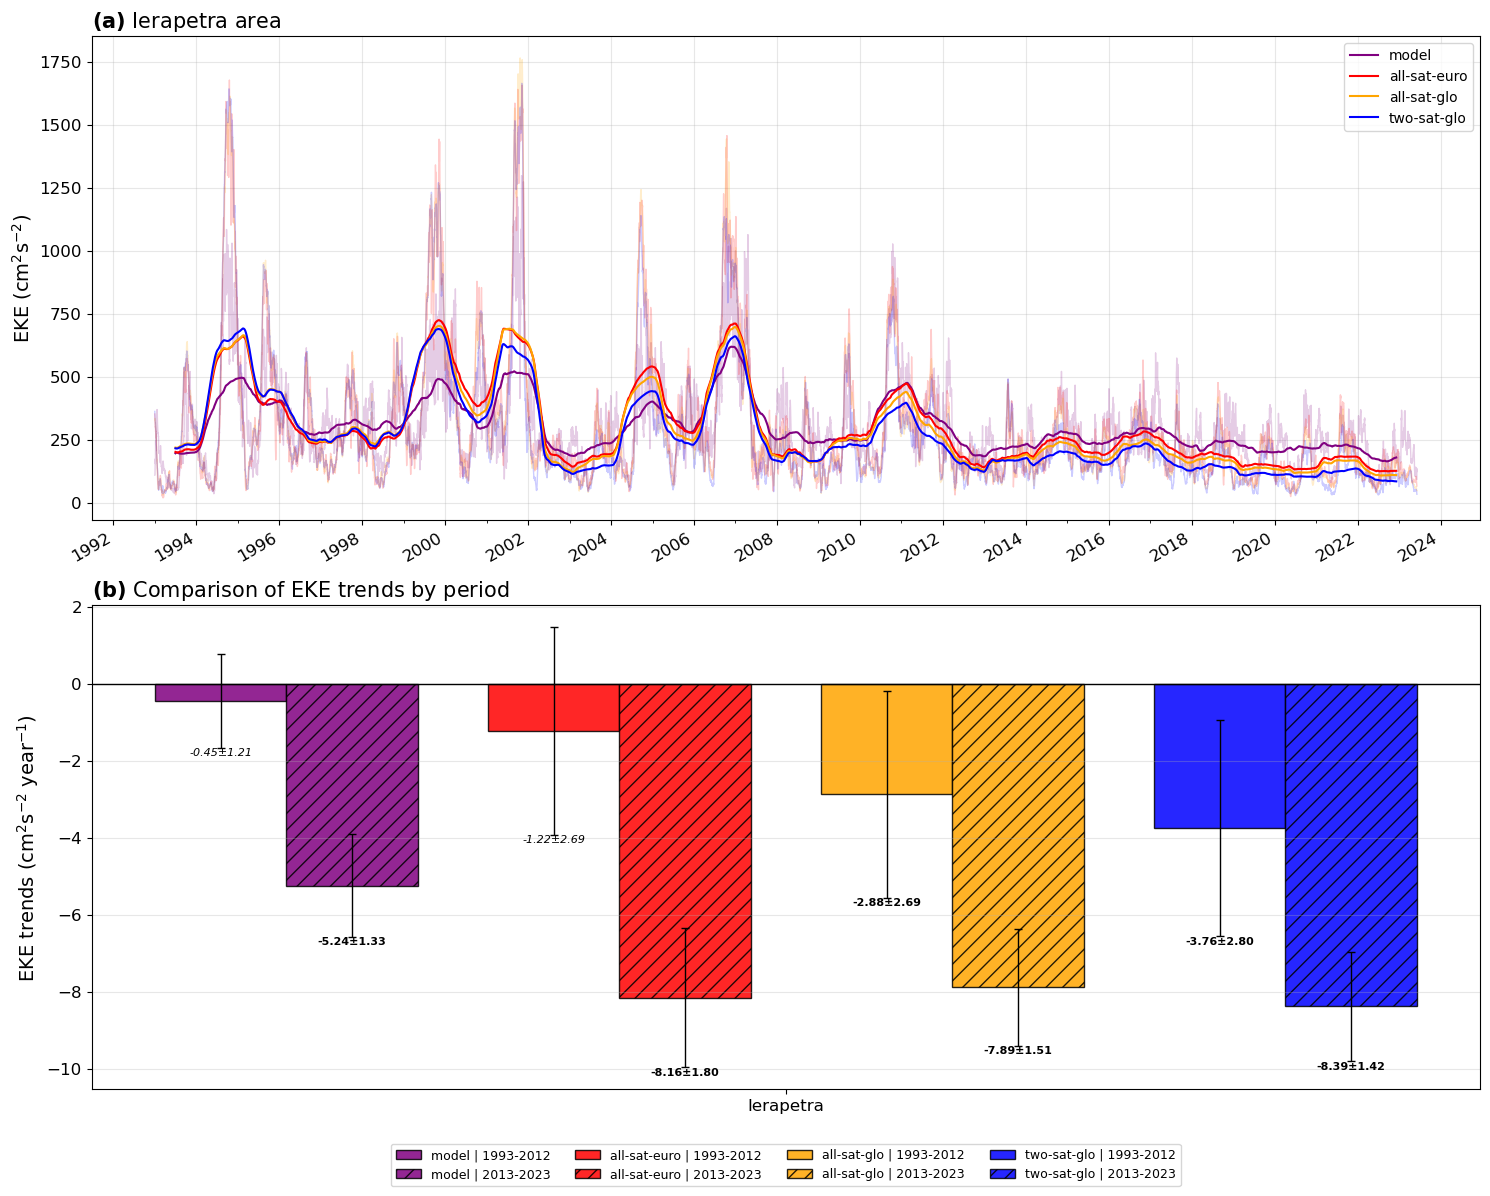

In [20]:
# ============================================================
# COMPARAISON DES TENDANCES PAR PERIODE
# ============================================================
regions = ['Ierapetra']
datasets = ['model', 'all-sat-euro', 'all-sat-glo', 'two-sat-glo']
colors = {
    'model': 'purple',
    'all-sat-euro': 'red',
    'all-sat-glo': 'orange',
    'two-sat-glo': 'blue'
}
period_names = list(periods.keys())

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(15, 12),
    gridspec_kw={'height_ratios': [1, 1]}
)
# ============================================================
# AXE 2 : TENDANCES
# ============================================================
x = np.arange(len(regions))
n_datasets = len(datasets)
n_periods = len(period_names)

bar_width = 0.075
dataset_spacing = 0.19

for i, dataset_name in enumerate(datasets):
    for j, period_name in enumerate(period_names):
        slopes = []
        errors = []
        pvalues = []
        for region in regions:
            res = results[region][dataset_name][period_name]
            slopes.append(res['slope'])
            errors.append(res['error'])
            pvalues.append(res['pvalue'])
        # Position des barres :
        offset_dataset = (
            i - (n_datasets - 1) / 2
        ) * dataset_spacing
        offset_period = (
            j - (n_periods - 1) / 2
        ) * bar_width
        positions = x + offset_dataset + offset_period
        for k, (slope, error, pvalue, xpos) in enumerate(zip(slopes, errors, pvalues, positions)):
            # Style de la barre
            if j == 0:
                hatch = None
            else:
                hatch = '//'
            # Significativité statistique
            significant = pvalue <= 0.05
            bar = ax2.bar(xpos, slope, width=bar_width, color=colors[dataset_name],
                alpha=0.85, edgecolor='black', hatch=hatch, label=(f'{dataset_name} | {period_name}' if k == 0 else None))
            ax2.errorbar(xpos, slope, yerr=error, fmt='none', ecolor='black', elinewidth=1, capsize=3)
            # Etiquette de la pente
            if slope >= 0:
                y = slope + error
                va = 'bottom'
            else:
                y = slope - error
                va = 'top'
            ax2.text(xpos, y, f'{slope:.2f}±{error:.2f}', ha='center', va=va, fontsize=8, 
                     fontweight='bold' if significant else 'normal', fontstyle='normal' if significant else 'italic')

ax2.axhline(0, color='black', linewidth=1)
ax2.set_xticks(x)
ax2.set_xticklabels(regions, fontsize=14)
ax2.set_ylabel('EKE trends (cm$^2$s$^{-2}$ year$^{-1}$)', fontsize=14)
ax2.set_title(r'$\bf{(b)}$ Comparison of EKE trends by period', fontsize=15, loc='left')
ax2.grid(True, axis='y', alpha=0.3)
ax2.legend(fontsize=9, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.10))



# ============================================================
# AXE 1 : IERAPETRA
# ============================================================

ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera, color='purple', lw=1, alpha=0.2)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE, color='red', lw=1, alpha=0.2)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE, color='orange', lw=1, alpha=0.2)
ax1.plot(dst_ierab.time, dst_ierab.EKE, color='blue', lw=1, alpha=0.2)

# Moyennes glissantes sur un an
ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera.rolling(time=365, center=True).mean(), color='purple', lw=1.5, label='model')
ax1.plot(dsm_ierab.time, dsm_ierab.EKE.rolling(time=365, center=True).mean(), color='red', lw=1.5, label='all-sat-euro')
ax1.plot(dsa_ierab.time, dsa_ierab.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1.5, label='all-sat-glo')
ax1.plot(dst_ierab.time, dst_ierab.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1.5, label='two-sat-glo')

ax1.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=14)
ax1.set_title(r'$\bf{(a)}$ Ierapetra area', fontsize=15, loc='left')
ax1.legend(fontsize=10, loc='upper right')
ax1.grid(True, alpha=0.3)
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(
    ax1.xaxis.get_majorticklabels(),
    rotation=30,
    ha='right'
)

for ax in [ax1, ax2]:
    ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# TENDANCES RELATIVES SUR LA PERIODE 1993-2023
# ============================================================
period_name = '1993-2023'
start, end = "1993-01-01", "2023-06-07"
results_relative = {}
for region, datasets in regions_data.items():
    results_relative[region] = {}
    for dataset_name, ds in datasets.items():
        ds_period = ds.sel(time=slice(start, end)).dropna(dim='time')
        eke_mean = ds_period.mean().item()
        sl, p, nns, inter = (pmk_test(ds_period) * np.array((365, 1, 1, 1)))
        incert = std_mktrend(ds_period, sl, inter, len(ds_period) / nns)

        sl_relative = sl / eke_mean * 100
        incert_relative = incert / eke_mean * 100
        results_relative[region][dataset_name] = {
            'period': period_name,
            'mean': eke_mean,
            'slope': sl,
            'error': incert,
            'pvalue': p,
            'intercept': inter,
            'slope_relative': sl_relative,
            'error_relative': incert_relative
        }
        print(
            f"{region} | {dataset_name} | {period_name}\n"
            f"  Mean EKE       = {eke_mean:.3f} cm²/s²\n"
            f"  Absolute trend = {sl:.3f} ± {incert:.3f} cm²/s²/year\n"
            f"  Relative trend = {sl_relative:.3f} ± "
            f"{incert_relative:.3f} %/year\n"
            f"  p-value        = {p:.4f}\n"
        )

Ierapetra | model | 1993-2023
  Mean EKE       = 300.128 cm²/s²
  Absolute trend = -3.615 ± 1.036 cm²/s²/year
  Relative trend = -1.205 ± 0.345 %/year
  p-value        = 0.0000

Ierapetra | all-sat-euro | 1993-2023
  Mean EKE       = 299.816 cm²/s²
  Absolute trend = -5.017 ± 2.407 cm²/s²/year
  Relative trend = -1.673 ± 0.803 %/year
  p-value        = 0.0001

Ierapetra | all-sat-glo | 1993-2023
  Mean EKE       = 288.498 cm²/s²
  Absolute trend = -5.646 ± 2.506 cm²/s²/year
  Relative trend = -1.957 ± 0.869 %/year
  p-value        = 0.0000

Ierapetra | two-sat-glo | 1993-2023
  Mean EKE       = 268.960 cm²/s²
  Absolute trend = -6.285 ± 2.481 cm²/s²/year
  Relative trend = -2.337 ± 0.923 %/year
  p-value        = 0.0000

Alboran | model | 1993-2023
  Mean EKE       = 292.092 cm²/s²
  Absolute trend = 1.561 ± 0.238 cm²/s²/year
  Relative trend = 0.535 ± 0.081 %/year
  p-value        = 0.0000

Alboran | all-sat-euro | 1993-2023
  Mean EKE       = 171.652 cm²/s²
  Absolute trend = 3.509 ±

In [ ]:
import ekmanstrat as eks
res = eks.main()

In [2]:
import ieraforcage as ief
res = ief.main()

[version] v5 : 4 saisons, lobe de pompage, APE, w par continuite, correlations decalees  |  fichier : /home/hargous/Argo/code/ieraforcage.py
[vg] vitesse max : 1.96 m/s (si > 5, vérifier VG_FACTOR : vitesses en cm/s ?)
[régions] eddy : 809 mailles (EKE >= 300) ; control : 2792 mailles (EKE < 150)
[mflux] variables : tauuo, tauvo
[contrôle] tau_y moyen JJA : -0.0463 N/m2 (attendu < 0 : Étésiens de nord). Sinon MODEL_SIGN = -1.
[lobe] 547 mailles (w_E <= -0.5 m/jour en JJA)
[uovo] variables : uo, vo
[uovo] Axe depth différent : sélection des profondeurs communes.
[uovo] Profondeurs conservées : 124 niveaux, 1.0182366371154785 à 4062.13037109375 m.
[strat] 2411 dates, 73 niveaux (<= 1000 m), 60x133 mailles, tuiles 10x10, blocs de 30 dates ; coupe à 34.229N ; dynamique : oui
  bloc 1/81  (1993-01-01)
  bloc 2/81  (1993-05-31)
  bloc 3/81  (1993-10-28)
  bloc 4/81  (1994-03-27)
  bloc 5/81  (1994-08-24)
  bloc 6/81  (1995-01-21)
  bloc 7/81  (1995-06-20)
  bloc 8/81  (1995-11-17)
  bloc 9/8

# Test

In [62]:
START = "1993-01-01"
END = "2023-06-07"

ERA5_FILE = "../../../data/era5_wind_01011993_31122025.nc"
MFLUX_FILE = "../../data/006_004_medmfc_mflux_iera.nc"

ERA5_TAUX = "avg_iews"
ERA5_TAUY = "avg_inss"
ERA5_SIGN = 1.0

MODEL_TAUX = None
MODEL_TAUY = None
MODEL_SIGN = 1.0

ERA5_DOMAIN = {"lon": (21.0, 29.5), "lat": (32.0, 36.5),}
FORCING_BOX = {"lon": (25.0, 27.5), "lat": (34.0, 35.2),}

WIND_MONTHS = (6, 7, 8)   # Juin, juillet, août : JJA
EKE_MONTHS = (8, 9, 10)   # Août, septembre, octobre : ASO

PERIOD1 = ("1993", "2012")
PERIOD2 = ("2013", "2023")

SMOOTH_DEG_ERA5 = 0.0
SMOOTH_DEG_MODEL = 0.0

RHO0 = 1025.0       # Masse volumique de référence (kg/m³)
OMEGA = 7.2921e-5   # Vitesse angulaire de rotation terrestre (rad/s)
R_EARTH = 6.371e6   # Rayon terrestre (m)

EDGE_TRIM = 2
OUTDIR = "out_ekman"

In [ ]:
START = "1993-01-01"
END = "2023-06-07"

ERA5_FILE = "../../../data/era5_wind_01011993_31122025.nc"
MFLUX_FILE = "../../data/006_004_medmfc_mflux_iera.nc"

ds_era5 = xr.open_dataset(ERA5_FILE)
ds_model = xr.open_dataset(MFLUX_FILE)

In [69]:
# Période d'étude
start = np.datetime64(START)
end = np.datetime64(END)

# Domaine exact de la grille MEDMFC
lon_min = float(ds_model.longitude.min())
lon_max = float(ds_model.longitude.max())
lat_min = float(ds_model.latitude.min())
lat_max = float(ds_model.latitude.max())

print("Domaine spatial commun :")
print(f"  Longitude : {lon_min:.4f}°E à {lon_max:.4f}°E")
print(f"  Latitude  : {lat_min:.4f}°N à {lat_max:.4f}°N")

# ------------------------------------------------------------
# ERA5
# Latitude décroissante : slice du maximum vers le minimum
# ------------------------------------------------------------

era5 = ds_era5.sel(
    valid_time=slice(start, end),
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max),
)

# ------------------------------------------------------------
# MEDMFC
# Latitude croissante : slice du minimum vers le maximum
# ------------------------------------------------------------

model = ds_model.sel(
    time=slice(start, end),
    latitude=slice(lat_min, lat_max),
    longitude=slice(lon_min, lon_max),
)

# ------------------------------------------------------------
# Vérifications
# ------------------------------------------------------------

for name, ds, time_name in [
    ("ERA5", era5, "valid_time"),
    ("MEDMFC", model, "time"),
]:
    print(f"\n{name}")
    print("Dimensions :", dict(ds.sizes))
    print(
        "Période :",
        pd.Timestamp(ds[time_name].values[0]),
        "→",
        pd.Timestamp(ds[time_name].values[-1]),
    )
    print(
        "Longitude :",
        float(ds.longitude.min()),
        "→",
        float(ds.longitude.max()),
    )
    print(
        "Latitude :",
        float(ds.latitude.min()),
        "→",
        float(ds.latitude.max()),
    )

Domaine spatial commun :
  Longitude : 22.5000°E à 28.0000°E
  Latitude  : 33.0208°N à 35.4792°N

ERA5
Dimensions : {'valid_time': 11115, 'latitude': 9, 'longitude': 23}
Période : 1993-01-01 00:00:00 → 2023-06-07 00:00:00
Longitude : 22.5 → 28.0
Latitude : 33.25 → 35.25

MEDMFC
Dimensions : {'time': 11115, 'latitude': 60, 'longitude': 133}
Période : 1993-01-01 00:00:00 → 2023-06-07 00:00:00
Longitude : 22.5 → 28.0
Latitude : 33.02083206176758 → 35.47916793823242


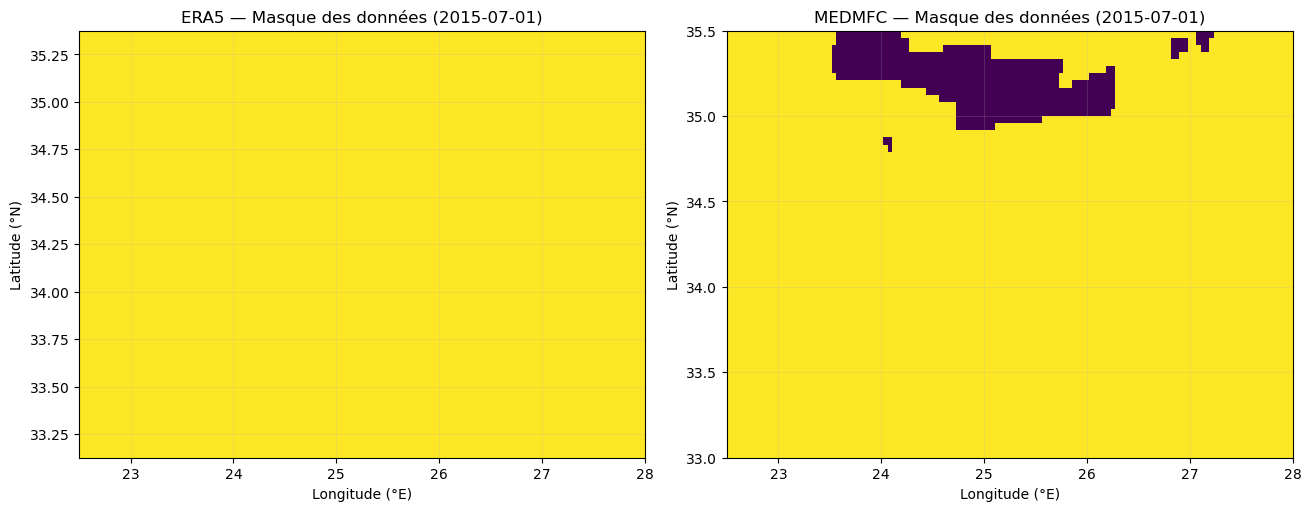

In [70]:
# ============================================================
# MASQUES ET DOMAINES SPATIAUX
# ============================================================

date_cible = np.datetime64("2015-07-01")

era5_day = era5.sel(valid_time=date_cible, method="nearest")
model_day = model.sel(time=date_cible, method="nearest")

mask_era5 = (
    era5_day["avg_iews"].notnull()
    & era5_day["avg_inss"].notnull()
)

mask_model = (
    model_day["tauuo"].notnull()
    & model_day["tauvo"].notnull()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

axes[0].pcolormesh(
    era5.longitude,
    era5.latitude,
    mask_era5,
    shading="auto",
    vmin=0,
    vmax=1,
)
axes[0].set_title(f"ERA5 — Masque des données ({str(era5_day.valid_time.values)[:10]})")
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")

axes[1].pcolormesh(
    model.longitude,
    model.latitude,
    mask_model,
    shading="auto",
    vmin=0,
    vmax=1,
)
axes[1].set_title(f"MEDMFC — Masque des données ({str(model_day.time.values)[:10]})")
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")

for ax in axes:
    ax.set_xlim(lon_min, lon_max)
    ax.grid(alpha=0.2)

plt.show()

In [71]:
# ============================================================
# CONSTANTES PHYSIQUES ET COORDONNÉES
# ============================================================

RHO0 = 1025.0       # kg m-3
OMEGA = 7.2921e-5   # rad s-1
R_EARTH = 6.371e6   # m

def coriolis(latitude):
    """Paramètre de Coriolis f en s-1 à partir de la latitude en degrés."""
    phi = np.deg2rad(latitude)
    return 2.0 * OMEGA * np.sin(phi)


# Paramètre de Coriolis sur chaque grille
f_era5 = coriolis(era5.latitude)
f_model = coriolis(model.latitude)

print("ERA5")
print(f"  f min : {float(f_era5.min()):.4e} s-1")
print(f"  f max : {float(f_era5.max()):.4e} s-1")

print("\nMEDMFC")
print(f"  f min : {float(f_model.min()):.4e} s-1")
print(f"  f max : {float(f_model.max()):.4e} s-1")

ERA5
  f min : 7.9964e-05 s-1
  f max : 8.4172e-05 s-1

MEDMFC
  f min : 7.9476e-05 s-1
  f max : 8.4648e-05 s-1


In [72]:
# ============================================================
# CALCUL DU POMPAGE D'EKMAN SANS LISSAGE
# ============================================================

def ekman_pumping(ds, tau_x_name, tau_y_name, time_name):
    """
    Calcule le pompage d'Ekman sur une grille latitude/longitude.

    Paramètres
    ----------
    ds : xarray.Dataset
        Jeu de données avec coordonnées latitude et longitude.
    tau_x_name, tau_y_name : str
        Noms des composantes zonale et méridienne du stress.
    time_name : str
        Nom de la coordonnée temporelle.

    Retour
    ------
    xarray.DataArray
        Pompage d'Ekman en m s-1.
    """

    lat = ds["latitude"]
    lon = ds["longitude"]

    # Stress de surface, en N m-2
    tau_x = ds[tau_x_name]
    tau_y = ds[tau_y_name]

    # Paramètre de Coriolis, avec dimensions compatibles
    phi = np.deg2rad(lat)
    f = 2.0 * OMEGA * np.sin(phi)

    # Quantités tau/f
    tau_x_over_f = tau_x / f
    tau_y_over_f = tau_y / f

    # Dérivées par rapport aux coordonnées en degrés.
    # Les dérivées xarray tiennent compte du sens des coordonnées.
    d_tauy_over_f_dlon = tau_y_over_f.differentiate("longitude")
    d_taux_over_f_dlat = tau_x_over_f.differentiate("latitude")

    # Conversion des gradients en degrés vers des gradients en mètres.
    # Les coordonnées angulaires doivent être exprimées en radians
    # dans les relations géométriques.
    dlon_rad = np.deg2rad(1.0)
    dlat_rad = np.deg2rad(1.0)

    dx_dlon = R_EARTH * np.cos(phi) * dlon_rad
    dy_dlat = R_EARTH * dlat_rad

    d_tauy_over_f_dx = d_tauy_over_f_dlon / dx_dlon
    d_taux_over_f_dy = d_taux_over_f_dlat / dy_dlat

    # Pompage d'Ekman
    wE = (d_tauy_over_f_dx - d_taux_over_f_dy) / RHO0

    wE.name = "ekman_pumping"
    wE.attrs["units"] = "m s-1"
    wE.attrs["long_name"] = "Ekman pumping velocity"

    return wE

In [74]:
# ============================================================
# TEST SUR UNE DATE
# ============================================================

date_cible = np.datetime64("2015-07-01")

era5_day = era5.sel(valid_time=date_cible, method="nearest")
model_day = model.sel(time=date_cible, method="nearest")

# Calcul sur une seule date
wE_era5_day = ekman_pumping(
    era5_day,
    tau_x_name="avg_iews",
    tau_y_name="avg_inss",
    time_name="valid_time",
)

wE_model_day = ekman_pumping(
    model_day,
    tau_x_name="tauuo",
    tau_y_name="tauvo",
    time_name="time",
)

In [ ]:
# ============================================================
# CALCUL DU POMPAGE D'EKMAN SUR TOUTE LA PÉRIODE
# TRAITEMENT ANNÉE PAR ANNÉE
# ============================================================

from pathlib import Path

# Dossier de sortie
OUTDIR = Path("../results/out_ekman")
PUMP_DIR = OUTDIR / "pumping_fields"
PUMP_DIR.mkdir(parents=True, exist_ok=True)

# Période
START_YEAR = 1993
END_YEAR = 2023

# Configuration des produits
products = {
    "ERA5": {
        "dataset": era5,
        "time_name": "valid_time",
        "tau_x": "avg_iews",
        "tau_y": "avg_inss",
    },
    "MEDMFC": {
        "dataset": model,
        "time_name": "time",
        "tau_x": "tauuo",
        "tau_y": "tauvo",
    },
}

# Résumé des résultats
summary_pumping = []

for product_name, info in products.items():

    print(f"\n{'=' * 65}")
    print(f"PRODUIT : {product_name}")
    print("=" * 65)

    ds = info["dataset"]
    time_name = info["time_name"]

    for year in range(START_YEAR, END_YEAR + 1):

        # Début et fin de l'année
        year_start = f"{year}-01-01"

        if year == END_YEAR:
            year_end = END
        else:
            year_end = f"{year}-12-31"

        # Sélection de l'année
        ds_year = ds.sel(
            {time_name: slice(year_start, year_end)}
        )

        if ds_year.sizes.get(time_name, 0) == 0:
            print(f"{year} : aucune donnée, année ignorée.")
            continue

        # Calcul du pompage d'Ekman
        wE_year = ekman_pumping(
            ds_year,
            tau_x_name=info["tau_x"],
            tau_y_name=info["tau_y"],
            time_name=time_name,
        )

        # Conversion en Dataset
        output_ds = wE_year.to_dataset(name="wE")

        output_ds.attrs.update({
            "product": product_name,
            "description": (
                "Ekman pumping computed without spatial smoothing"
            ),
            "rho0_kg_m3": RHO0,
            "omega_rad_s": OMEGA,
            "earth_radius_m": R_EARTH,
            "period_start": year_start,
            "period_end": year_end,
        })

        # Sauvegarde d'un fichier par année
        output_file = (
            PUMP_DIR / f"wE_{product_name}_{year}.nc"
        )

        output_ds.to_netcdf(output_file)

        summary_pumping.append({
            "product": product_name,
            "year": year,
            "n_times": ds_year.sizes[time_name],
            "file": str(output_file),
        })

        print(
            f"{year} : {ds_year.sizes[time_name]} dates "
            f"| sauvegardé : {output_file.name}"
        )

        # Libérer les références à ce bloc annuel
        del output_ds, wE_year, ds_year

print("\nCalcul terminé.")


PRODUIT : ERA5
1993 : 365 dates | sauvegardé : wE_ERA5_1993.nc
1994 : 365 dates | sauvegardé : wE_ERA5_1994.nc
1995 : 365 dates | sauvegardé : wE_ERA5_1995.nc
1996 : 366 dates | sauvegardé : wE_ERA5_1996.nc
1997 : 365 dates | sauvegardé : wE_ERA5_1997.nc
1998 : 365 dates | sauvegardé : wE_ERA5_1998.nc
1999 : 365 dates | sauvegardé : wE_ERA5_1999.nc
2000 : 366 dates | sauvegardé : wE_ERA5_2000.nc
2001 : 365 dates | sauvegardé : wE_ERA5_2001.nc
2002 : 365 dates | sauvegardé : wE_ERA5_2002.nc
2003 : 365 dates | sauvegardé : wE_ERA5_2003.nc
2004 : 366 dates | sauvegardé : wE_ERA5_2004.nc
2005 : 365 dates | sauvegardé : wE_ERA5_2005.nc
2006 : 365 dates | sauvegardé : wE_ERA5_2006.nc
2007 : 365 dates | sauvegardé : wE_ERA5_2007.nc
2008 : 366 dates | sauvegardé : wE_ERA5_2008.nc
2009 : 365 dates | sauvegardé : wE_ERA5_2009.nc
2010 : 365 dates | sauvegardé : wE_ERA5_2010.nc
2011 : 365 dates | sauvegardé : wE_ERA5_2011.nc
2012 : 366 dates | sauvegardé : wE_ERA5_2012.nc
2013 : 365 dates | sauve

,product,year,n_times,file
0,ERA5,1993,365,../results/out_ekman/pumping_fields/wE_ERA5_19...
1,ERA5,1994,365,../results/out_ekman/pumping_fields/wE_ERA5_19...
2,ERA5,1995,365,../results/out_ekman/pumping_fields/wE_ERA5_19...
3,ERA5,1996,366,../results/out_ekman/pumping_fields/wE_ERA5_19...
4,ERA5,1997,365,../results/out_ekman/pumping_fields/wE_ERA5_19...
...,...,...,...,...
57,MEDMFC,2019,365,../results/out_ekman/pumping_fields/wE_MEDMFC_...
58,MEDMFC,2020,366,../results/out_ekman/pumping_fields/wE_MEDMFC_...
59,MEDMFC,2021,365,../results/out_ekman/pumping_fields/wE_MEDMFC_...
60,MEDMFC,2022,365,../results/out_ekman/pumping_fields/wE_MEDMFC_...


In [78]:
# ============================================================
# POMPAGES D'EKMAN MOYENS PAR SAISON
# Calcul à partir du stress moyen saisonnier
# ============================================================

seasons = {
    "Hiver (DJF)": [12, 1, 2],
    "Printemps (MAM)": [3, 4, 5],
    "Été (JJA)": [6, 7, 8],
    "Automne (SON)": [9, 10, 11],
}

seasonal_pumping = {}

for product_name, info in products.items():

    ds = info["dataset"]
    time_name = info["time_name"]

    seasonal_pumping[product_name] = {}

    for season_name, months in seasons.items():

        # Sélection des mois correspondant à la saison
        seasonal_ds = ds.sel(
            {time_name: slice(START, END)}
        )

        seasonal_ds = seasonal_ds.where(
            seasonal_ds[time_name].dt.month.isin(months),
            drop=True,
        )

        # Moyenne temporelle des composantes du stress
        tau_x_mean = seasonal_ds[info["tau_x"]].mean(
            dim=time_name, skipna=True
        )
        tau_y_mean = seasonal_ds[info["tau_y"]].mean(
            dim=time_name, skipna=True
        )

        # Dataset contenant les stress moyens
        stress_mean_ds = xr.Dataset({
            info["tau_x"]: tau_x_mean,
            info["tau_y"]: tau_y_mean,
        })

        # Calcul du pompage à partir du stress moyen saisonnier
        wE_season = ekman_pumping(
            stress_mean_ds,
            tau_x_name=info["tau_x"],
            tau_y_name=info["tau_y"],
            time_name=time_name,
        )

        seasonal_pumping[product_name][season_name] = wE_season

        print(
            f"{product_name} — {season_name} : "
            f"{seasonal_ds.sizes[time_name]} dates"
        )

ERA5 — Hiver (DJF) : 2766 dates
ERA5 — Printemps (MAM) : 2852 dates
ERA5 — Été (JJA) : 2767 dates
ERA5 — Automne (SON) : 2730 dates
MEDMFC — Hiver (DJF) : 2766 dates
MEDMFC — Printemps (MAM) : 2852 dates
MEDMFC — Été (JJA) : 2767 dates
MEDMFC — Automne (SON) : 2730 dates


vmin = -16.000 m/jour
vmax = 6.903 m/jour


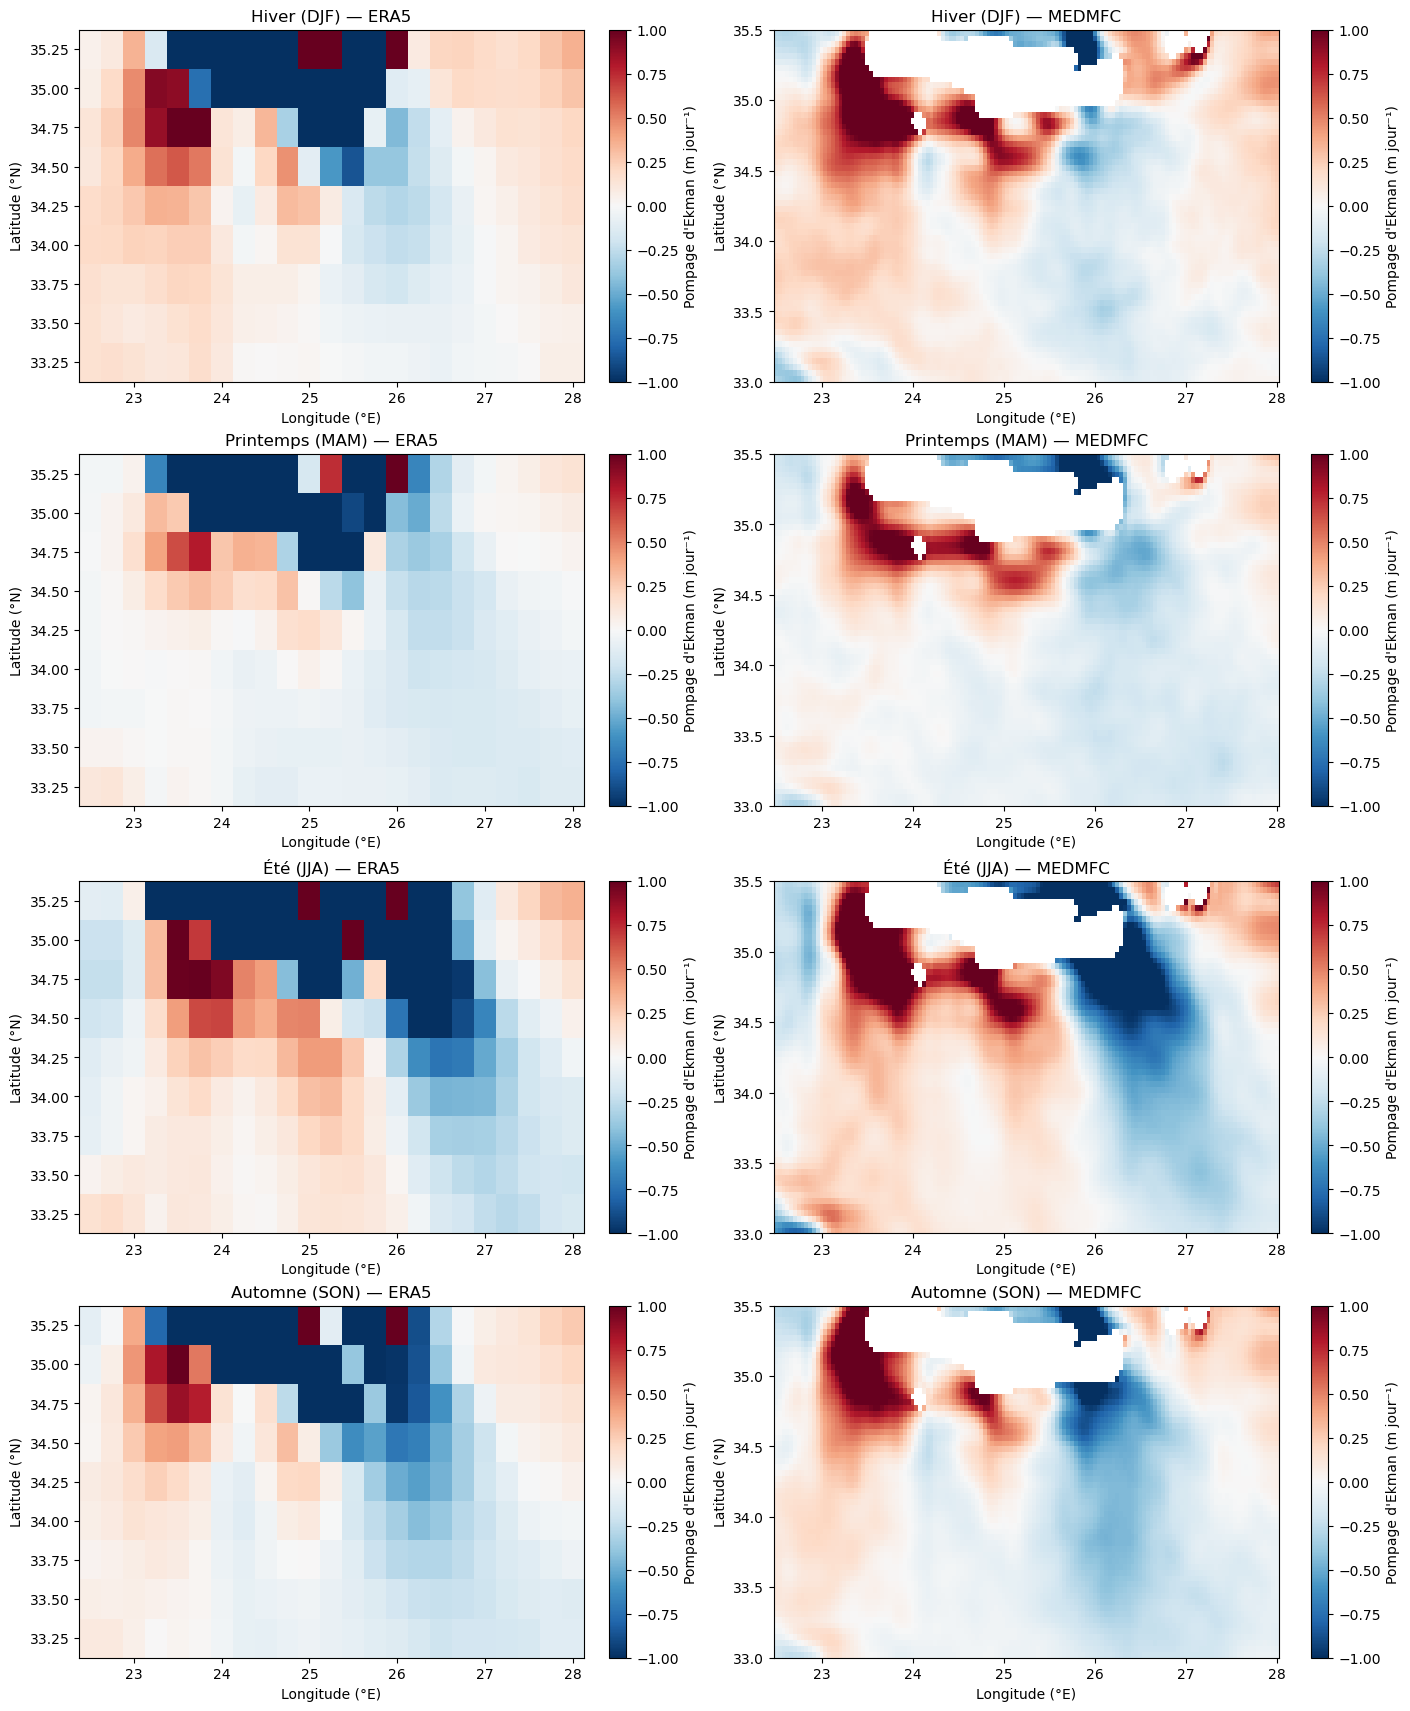

In [95]:
# ============================================================
# FIGURE SAISONNIÈRE : ERA5 ET MEDMFC
# ============================================================

fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 17),
    constrained_layout=True,
)

# ------------------------------------------------------------
# 1. Limites communes de la colorbar (m/jour)
# ------------------------------------------------------------

all_values = []

for product_name in ["ERA5", "MEDMFC"]:
    for season_name in seasons:
        field = seasonal_pumping[product_name][season_name] * 86400

        values = field.values
        valid = values[np.isfinite(values)]

        if valid.size:
            all_values.append(valid)

all_values = np.concatenate(all_values)

vmin = float(np.nanmin(all_values))
vmax = float(np.nanmax(all_values))

print(f"vmin = {vmin:.3f} m/jour")
print(f"vmax = {vmax:.3f} m/jour")

# ------------------------------------------------------------
# 2. Tracé des quatre saisons pour les deux produits
# ------------------------------------------------------------

for i, (season_name, months) in enumerate(seasons.items()):

    for j, product_name in enumerate(["ERA5", "MEDMFC"]):

        field = seasonal_pumping[product_name][season_name] * 86400
        ds_plot = products[product_name]["dataset"]

        im = axes[i, j].pcolormesh(
            ds_plot.longitude,
            ds_plot.latitude,
            field,
            shading="auto",
            cmap="RdBu_r",
            vmin=-1,
            vmax=1,
        )

        axes[i, j].set_title(f"{season_name} — {product_name}")
        axes[i, j].set_xlabel("Longitude (°E)")
        axes[i, j].set_ylabel("Latitude (°N)")

        fig.colorbar(
            im,
            ax=axes[i, j],
            label="Pompage d'Ekman (m jour⁻¹)",
        )

plt.show()

In [99]:
# ============================================================
# 1. CHARGER LE MASQUE EKE ORIGINAL
# ============================================================

mask_eke = np.load(
    '../../../Med_Global_EKE/results/masks/2mask_IERAISO_MED.npy',
    allow_pickle=True
)

ekem = xr.open_dataset(
    '../../../Med_Global_EKE/processed_data/MED/ALL_SAT/'
    'NEKE_ALL_SAT_MED_C3S_vDT2021_19930101_20230607.nc'
)

meanekem = ekem.mean(dim='time', skipna=False)

lon_eke = meanekem['lon'].values
lat_eke = meanekem['lat'].values

print("Dimensions du masque EKE :", mask_eke.shape)
print("Dimensions de la grille EKE :", len(lat_eke), len(lon_eke))

assert mask_eke.shape == (len(lat_eke), len(lon_eke)), \
    "Le masque ne correspond pas aux dimensions de la grille EKE."

# ============================================================
# 2. CONSTRUIRE LE POLYGONE
# ============================================================

dlon_eke = np.abs(np.diff(lon_eke).mean())
dlat_eke = np.abs(np.diff(lat_eke).mean())

half_dlon_eke = dlon_eke / 2
half_dlat_eke = dlat_eke / 2

cells = []

for j, lat0 in enumerate(lat_eke):
    for i, lon0 in enumerate(lon_eke):

        if mask_eke[j, i]:
            cells.append(
                box(
                    lon0 - half_dlon_eke,
                    lat0 - half_dlat_eke,
                    lon0 + half_dlon_eke,
                    lat0 + half_dlat_eke
                )
            )

polygon_iera = unary_union(cells)

print("Polygone construit.")
print("Géométrie valide :", polygon_iera.is_valid)
print("Nombre de cellules sources :", len(cells))

Dimensions du masque EKE : (136, 344)
Dimensions de la grille EKE : 136 344
Polygone construit.
Géométrie valide : True
Nombre de cellules sources : 155


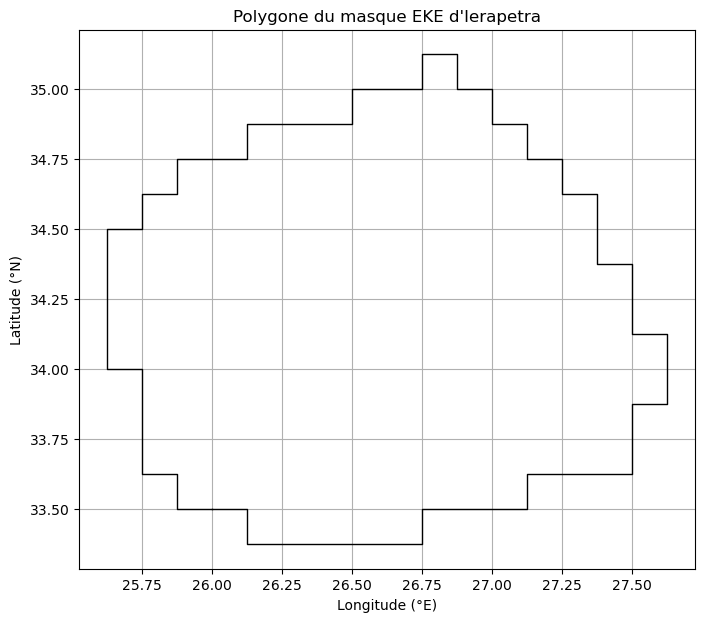

In [100]:
fig, ax = plt.subplots(figsize=(8, 7))

x, y = polygon_iera.exterior.xy if polygon_iera.geom_type == "Polygon" else (None, None)

if x is not None:
    ax.plot(x, y, color="black", linewidth=1)

else:
    for geom in polygon_iera.geoms:
        if geom.geom_type == "Polygon":
            x, y = geom.exterior.xy
            ax.plot(x, y, color="black", linewidth=1)

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Polygone du masque EKE d'Ierapetra")
ax.set_aspect("equal")
ax.grid()
plt.show()

In [101]:
# ============================================================
# FONCTION : TRANSFÉRER LE POLYGONE SUR UNE GRILLE
# ============================================================

def build_mask_on_grid(lon, lat, polygon, name="mask_iera"):

    lon = np.asarray(lon)
    lat = np.asarray(lat)

    dlon = np.abs(np.diff(lon).mean())
    dlat = np.abs(np.diff(lat).mean())

    half_dlon = dlon / 2
    half_dlat = dlat / 2

    mask_grid = np.zeros((len(lat), len(lon)), dtype=bool)

    for j, lat0 in enumerate(lat):
        for i, lon0 in enumerate(lon):

            cell = box(
                lon0 - half_dlon,
                lat0 - half_dlat,
                lon0 + half_dlon,
                lat0 + half_dlat
            )

            mask_grid[j, i] = cell.intersects(polygon)

    return xr.DataArray(
        mask_grid,
        coords={
            "latitude": lat,
            "longitude": lon
        },
        dims=("latitude", "longitude"),
        name=name
    )

In [102]:
# ============================================================
# MASQUES ERA5 ET MEDMFC
# ============================================================

mask_era5 = build_mask_on_grid(
    lon=era5.longitude.values,
    lat=era5.latitude.values,
    polygon=polygon_iera,
    name="mask_iera_era5"
)

mask_model = build_mask_on_grid(
    lon=model.longitude.values,
    lat=model.latitude.values,
    polygon=polygon_iera,
    name="mask_iera_medmfc"
)

print("Nombre de points sélectionnés :")
print("ERA5   :", int(mask_era5.sum()))
print("MEDMFC :", int(mask_model.sum()))

Nombre de points sélectionnés :
ERA5   : 66
MEDMFC : 1535


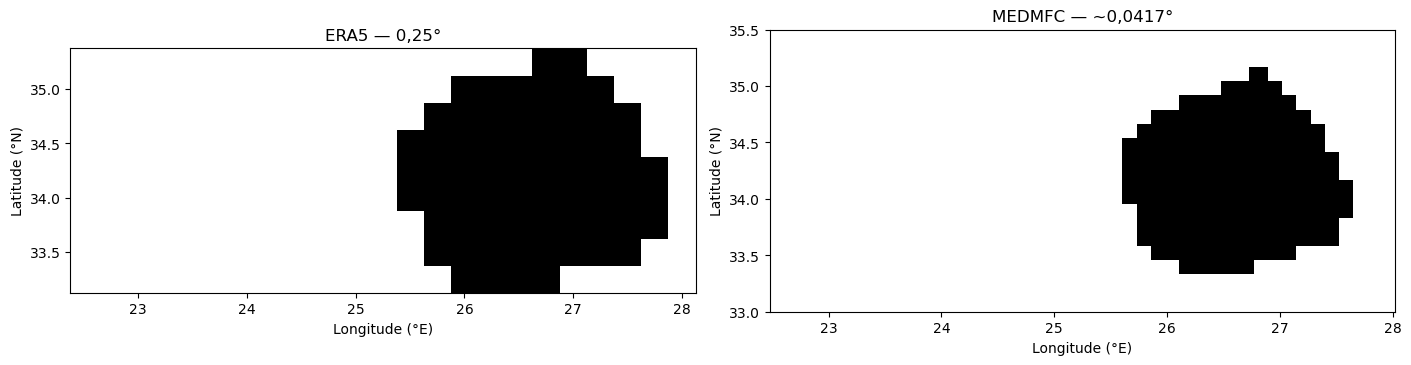

In [103]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

for ax, mask_grid, title in [
    (axes[0], mask_era5, "ERA5 — 0,25°"),
    (axes[1], mask_model, "MEDMFC — ~0,0417°")
]:

    im = ax.pcolormesh(
        mask_grid.longitude,
        mask_grid.latitude,
        mask_grid.astype(int),
        shading="auto",
        cmap="Greys",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    ax.set_aspect("equal")

plt.show()

In [104]:
# ============================================================
# FONCTION : MOYENNE SPATIALE PONDÉRÉE PAR L'AIRE
# ============================================================

def spatial_mean_weighted(field, mask):
    """
    Moyenne spatiale pondérée par cos(latitude),
    dans la région définie par mask.

    Les valeurs manquantes sont exclues de la moyenne
    et les poids sont renormalisés à chaque date.
    """

    # Vérifier que le masque correspond aux coordonnées du champ
    mask = mask.sel(
        latitude=field.latitude,
        longitude=field.longitude,
    )

    # Poids surfaciques approximatifs
    weights = np.cos(np.deg2rad(field.latitude))

    # Sélection de la région
    field_masked = field.where(mask)

    # Moyenne pondérée, avec renormalisation sur les cellules valides
    numerator = (field_masked * weights).sum(
        dim=("latitude", "longitude"),
        skipna=True,
    )

    denominator = weights.where(
        field_masked.notnull()
    ).sum(
        dim=("latitude", "longitude"),
        skipna=True,
    )

    result = numerator / denominator
    result.name = "ekman_pumping_mean"
    result.attrs["units"] = "m s-1"

    return result

In [105]:
# ============================================================
# SÉRIES TEMPORELLES DU POMPAGE D'EKMAN
# ============================================================

# Calcul sur le domaine spatial commun, avant application du masque
wE_era5 = ekman_pumping(
    era5,
    "avg_iews",
    "avg_inss",
    "valid_time",
)

wE_model = ekman_pumping(
    model,
    "tauuo",
    "tauvo",
    "time",
)

# Moyenne spatiale dans la région d'Ierapetra
wE_iera_era5 = spatial_mean_weighted(
    wE_era5,
    mask_era5,
)

wE_iera_model = spatial_mean_weighted(
    wE_model,
    mask_model,
)

print("ERA5 :", wE_iera_era5)
print("MEDMFC :", wE_iera_model)

ERA5 : <xarray.DataArray 'ekman_pumping_mean' (valid_time: 11115)> Size: 89kB
array([ 2.31186118e-06,  7.69070887e-06,  2.27229518e-06, ...,
       -6.64591550e-06, -3.93251319e-06, -9.19283812e-07], shape=(11115,))
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 89kB 1993-01-01 ... 2023-06-07
Attributes:
    units:    m s-1
MEDMFC : <xarray.DataArray 'ekman_pumping_mean' (time: 11115)> Size: 89kB
array([ 1.86746903e-06,  4.04199756e-06,  7.83730778e-07, ...,
       -8.24349062e-06, -3.15616745e-06, -1.67804772e-06], shape=(11115,))
Coordinates:
  * time     (time) datetime64[ns] 89kB 1993-01-01 1993-01-02 ... 2023-06-07
Attributes:
    units:    m s-1


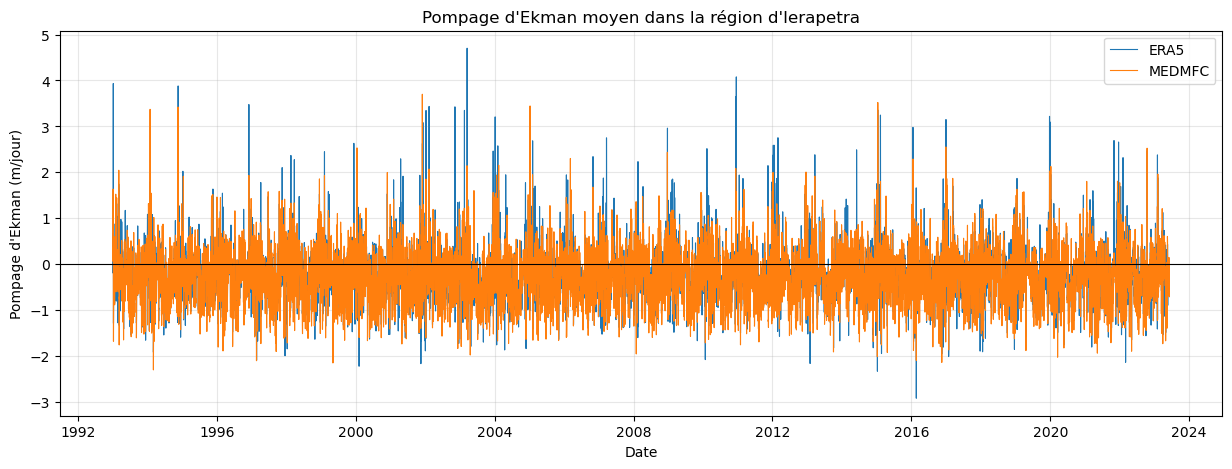

In [106]:
# ============================================================
# PREMIER GRAPHIQUE : POMPAGE D'EKMAN MOYEN À IERAPETRA
# ============================================================

fig, ax = plt.subplots(figsize=(15, 5))

(wE_iera_era5 * 86400).plot(
    ax=ax,
    label="ERA5",
    linewidth=0.8,
)

(wE_iera_model * 86400).plot(
    ax=ax,
    label="MEDMFC",
    linewidth=0.8,
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Pompage d'Ekman moyen dans la région d'Ierapetra")
ax.set_ylabel("Pompage d'Ekman (m/jour)")
ax.set_xlabel("Date")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [109]:
# ============================================================
# 1. ALIGNEMENT TEMPOREL
# ============================================================

# Convertir en pandas Series avec un index temporel
s_era5 = wE_iera_era5.to_series()
s_model = wE_iera_model.to_series()

s_era5.index = pd.to_datetime(s_era5.index)
s_model.index = pd.to_datetime(s_model.index)

# Moyenne journalière (utile si plusieurs valeurs par jour)
s_era5_daily = s_era5.resample("1D").mean()
s_model_daily = s_model.resample("1D").mean()

# Conserver uniquement les dates communes
df_corr = pd.concat(
    [
        s_era5_daily.rename("ERA5"),
        s_model_daily.rename("MEDMFC"),
    ],
    axis=1,
    join="inner",
).dropna()

print("Première date :", df_corr.index.min())
print("Dernière date :", df_corr.index.max())
print("Nombre de paires :", len(df_corr))
print("\nRésumé statistique :")
display(df_corr.describe())

Première date : 1993-01-01 00:00:00
Dernière date : 2023-06-07 00:00:00
Nombre de paires : 11115

Résumé statistique :


,ERA5,MEDMFC
count,1.111500e+04,1.111500e+04
mean,-2.483689e-06,-3.034198e-06
std,6.127222e-06,6.390007e-06
min,-3.377066e-05,-2.663165e-05
25%,-5.989070e-06,-6.889475e-06
50%,-2.253094e-06,-2.603646e-06
75%,3.947972e-07,4.184517e-07
max,5.441788e-05,4.282126e-05


In [112]:
# ============================================================
# 2. CORRÉLATION ERA5 - MEDMFC
# ============================================================

r, p_value = stats.pearsonr(
    df_corr["ERA5"],
    df_corr["MEDMFC"],
)

rmse = np.sqrt(
    np.mean((df_corr["ERA5"] - df_corr["MEDMFC"])**2)
)

bias = np.mean(df_corr["MEDMFC"] - df_corr["ERA5"])

print("Corrélation ERA5 - MEDMFC")
print("--------------------------")
print(f"N     = {len(df_corr)}")
print(f"r     = {r:.3f}")
print(f"p     = {p_value:.3e}")
print(f"RMSE  = {rmse * 86400:.4f} m/jour")
print(f"Bias  = {bias * 86400:.4f} m/jour")

Corrélation ERA5 - MEDMFC
--------------------------
N     = 11115
r     = 0.665
p     = 0.000e+00
RMSE  = 0.4454 m/jour
Bias  = -0.0476 m/jour


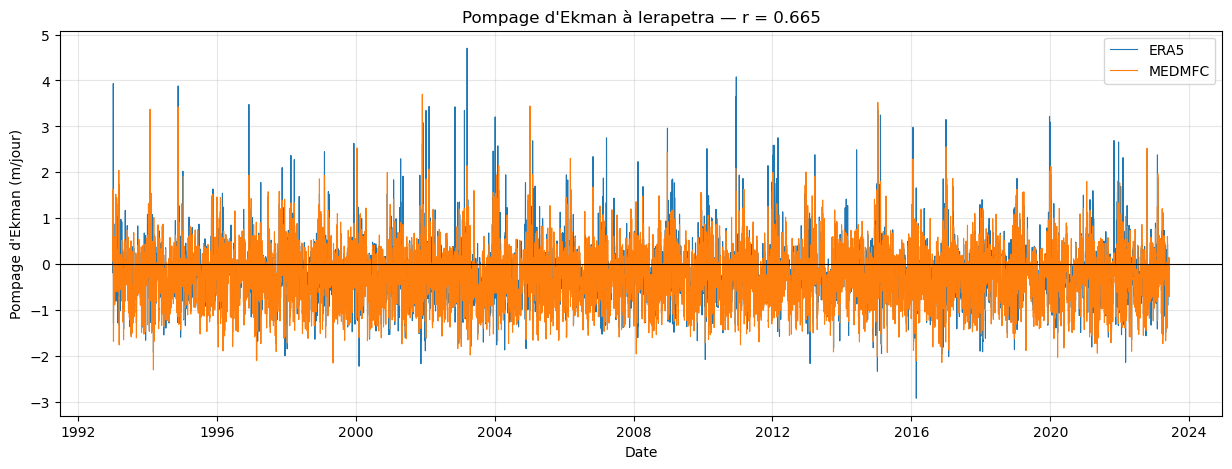

In [114]:
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    df_corr.index,
    df_corr["ERA5"] * 86400,
    label="ERA5",
    linewidth=0.8,
)

ax.plot(
    df_corr.index,
    df_corr["MEDMFC"] * 86400,
    label="MEDMFC",
    linewidth=0.8,
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Pompage d'Ekman (m/jour)")
ax.set_xlabel("Date")
ax.set_title(f"Pompage d'Ekman à Ierapetra — r = {r:.3f}")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [115]:
# ============================================================
# CORRELATION ERA5 vs MEDMFC PAR SAISON
# ============================================================

# Associer chaque observation à une saison météorologique
season_map = {
    12: "Winter",
    1:  "Winter",
    2:  "Winter",
    3:  "Spring",
    4:  "Spring",
    5:  "Spring",
    6:  "Summer",
    7:  "Summer",
    8:  "Summer",
    9:  "Fall",
    10: "Fall",
    11: "Fall",
}

df_seasonal = df_corr.copy()
df_seasonal["season"] = df_seasonal.index.month.map(season_map)

# Calculer les statistiques
seasonal_results = []

for season in ["Winter", "Spring", "Summer", "Fall"]:

    df_s = df_seasonal[df_seasonal["season"] == season]

    x = df_s["ERA5"].values
    y = df_s["MEDMFC"].values

    # Vérifier qu'il existe suffisamment de données
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    if len(x) < 3:
        continue

    r, p_value = stats.pearsonr(x, y)

    rmse = np.sqrt(np.mean((y - x)**2))
    bias = np.mean(y - x)
    mae = np.mean(np.abs(y - x))

    seasonal_results.append({
        "Season": season,
        "N_days": len(x),
        "Pearson_r": r,
        "p_value": p_value,
        "RMSE_m_day": rmse * 86400,
        "MAE_m_day": mae * 86400,
        "Bias_m_day": bias * 86400,
    })

df_seasonal_results = pd.DataFrame(seasonal_results).set_index("Season")

display(df_seasonal_results.round(4))

,N_days,Pearson_r,p_value,RMSE_m_day,MAE_m_day,Bias_m_day
Season,,,,,,
Winter,2766,0.5407,0.0,0.6158,0.4014,-0.0343
Spring,2852,0.6303,0.0,0.4258,0.2849,-0.0353
Summer,2767,0.8005,0.0,0.3154,0.2304,-0.0756
Fall,2730,0.7205,0.0,0.3649,0.2435,-0.0454


In [118]:
# ============================================================
# CORRELATION ENTRE MOYENNES SAISONNIERES ANNUELLES
# ============================================================

df_annual = df_corr.copy()

df_annual["year"] = df_annual.index.year
df_annual["season"] = df_annual.index.month.map(season_map)

# Moyennes annuelles pour chaque saison
annual_seasonal = (
    df_annual
    .groupby(["year", "season"])[["ERA5", "MEDMFC"]]
    .mean()
)

results_annual = []

for season in ["Winter", "Spring", "Summer", "Fall"]:

    df_s = annual_seasonal.xs(season, level="season").dropna()

    x = df_s["ERA5"].values
    y = df_s["MEDMFC"].values

    if len(x) < 3:
        continue

    r, p_value = stats.pearsonr(x, y)

    rmse = np.sqrt(np.mean((y - x)**2))
    mae = np.mean(np.abs(y - x))
    bias = np.mean(y - x)

    results_annual.append({
        "Season": season,
        "N_years": len(x),
        "Pearson_r": r,
        "p_value": p_value,
        "RMSE_m_day": rmse * 86400,
        "MAE_m_day": mae * 86400,
        "Bias_m_day": bias * 86400,
    })

df_annual_results = (
    pd.DataFrame(results_annual)
    .set_index("Season")
)

display(df_annual_results.round(4))

,N_years,Pearson_r,p_value,RMSE_m_day,MAE_m_day,Bias_m_day
Season,,,,,,
Winter,31,0.8032,0.0,0.0607,0.0447,-0.0345
Spring,31,0.8180,0.0,0.0476,0.0411,-0.0353
Summer,31,0.9391,0.0,0.0831,0.0761,-0.0718
Fall,30,0.9135,0.0,0.0610,0.0479,-0.0454


In [121]:
# ============================================================
# PREPARER LES DEUX SERIES TEMPORELLES
# ============================================================

# Convertir chaque série en DataArray avec une coordonnée temporelle "time"
era5_ts = wE_iera_era5.rename({"valid_time": "time"}) \
    if "valid_time" in wE_iera_era5.dims else wE_iera_era5

model_ts = wE_iera_model.rename({"time": "time"})

# Conversion en séries pandas pour harmoniser les dates
s_era5 = era5_ts.to_series()
s_model = model_ts.to_series()

s_era5.index = pd.to_datetime(s_era5.index)
s_model.index = pd.to_datetime(s_model.index)

# Réunir les produits sur les dates communes
df_wE_iera = pd.concat(
    [
        s_era5.rename("ERA5"),
        s_model.rename("MEDMFC")
    ],
    axis=1,
    join="inner"
).sort_index()

print("Première date :", df_wE_iera.index.min())
print("Dernière date :", df_wE_iera.index.max())
print("Nombre de dates communes :", len(df_wE_iera))

display(df_wE_iera.head())

Première date : 1993-01-01 00:00:00
Dernière date : 2023-06-07 00:00:00
Nombre de dates communes : 11115


,ERA5,MEDMFC
time,,
1993-01-01,0.000002,1.867469e-06
1993-01-02,0.000008,4.041998e-06
1993-01-03,0.000002,7.837308e-07
1993-01-04,-0.000002,3.386842e-06
1993-01-05,0.000006,9.181048e-06


In [122]:
# ============================================================
# MOYENNES SAISONNIERES ANNUELLES
# ============================================================

df_seasonal = df_wE_iera.copy()

df_seasonal["year"] = df_seasonal.index.year
df_seasonal["month"] = df_seasonal.index.month

season_months = {
    "Winter": [12, 1, 2],
    "Spring": [3, 4, 5],
    "Summer": [6, 7, 8],
    "Fall": [9, 10, 11],
}

seasonal_series = {}

for season, months in season_months.items():

    df_s = df_seasonal[
        df_seasonal["month"].isin(months)
    ].copy()

    if season == "Winter":
        df_s["season_year"] = np.where(
            df_s["month"] == 12,
            df_s["year"] + 1,
            df_s["year"]
        )
    else:
        df_s["season_year"] = df_s["year"]

    seasonal_series[season] = (
        df_s.groupby("season_year")[["ERA5", "MEDMFC"]]
        .mean()
    )

display(seasonal_series["Summer"].head())

,ERA5,MEDMFC
season_year,,
1993,-0.000005,-0.000006
1994,-0.000005,-0.000006
1995,-0.000004,-0.000004
1996,-0.000006,-0.000007
1997,-0.000004,-0.000004


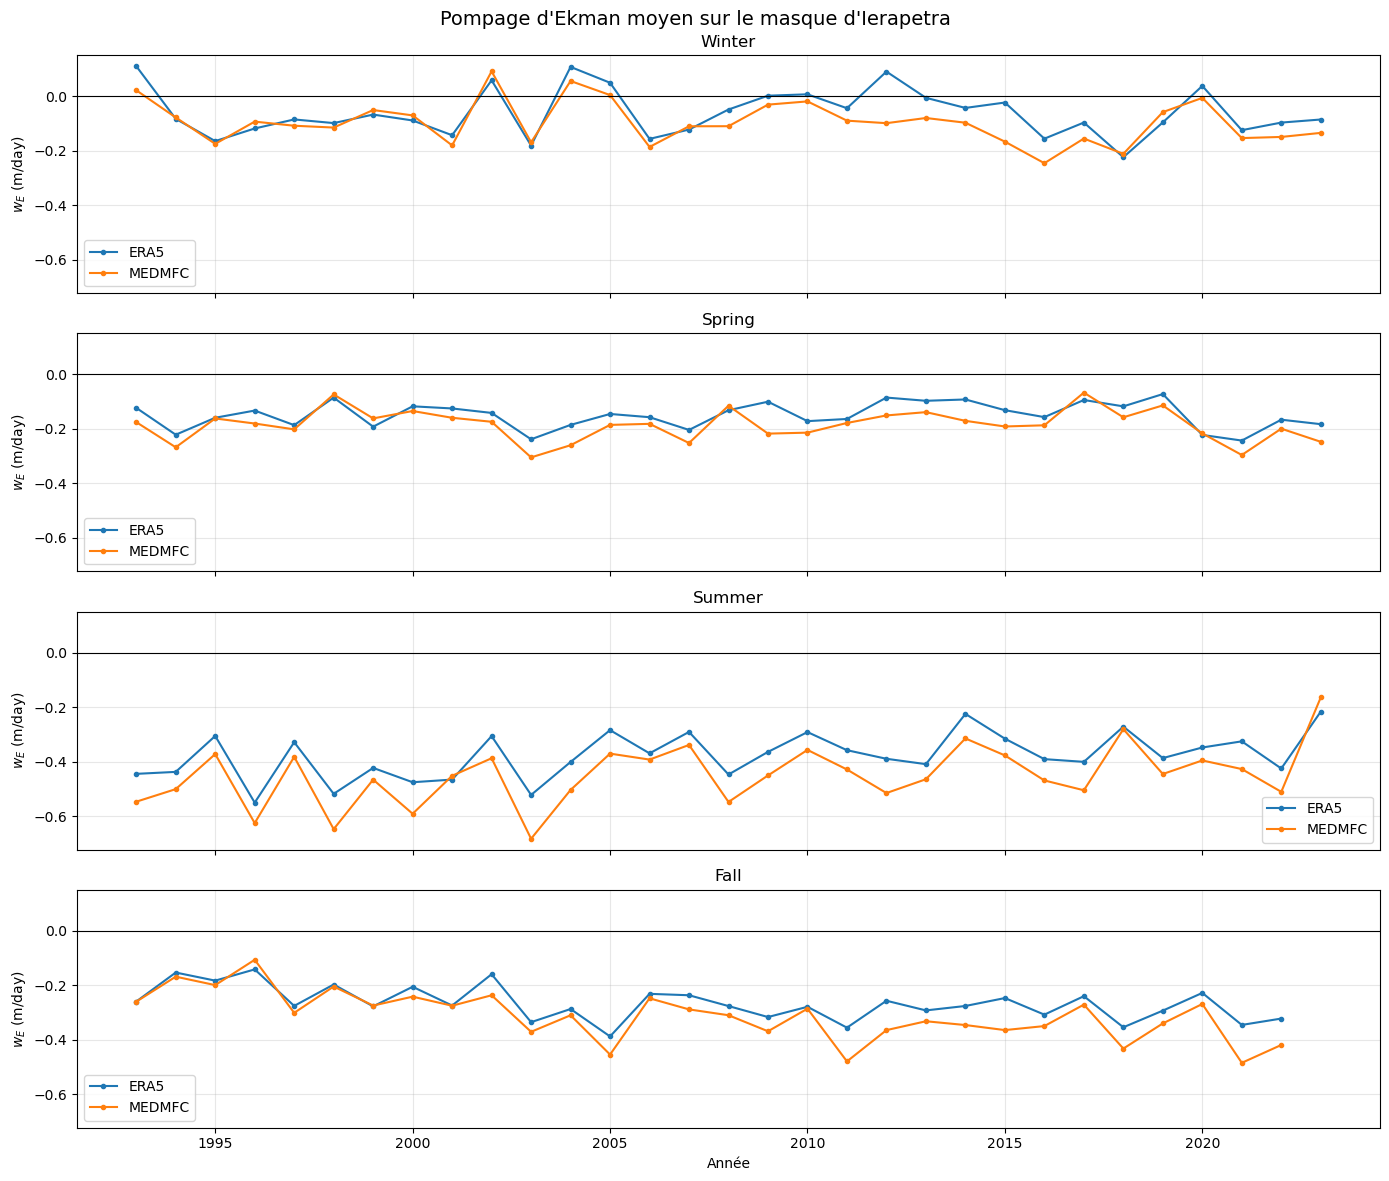

In [123]:
# ============================================================
# PLOT DES SERIES TEMPORELLES SAISONNIERES
# ============================================================

seasons = ["Winter", "Spring", "Summer", "Fall"]

fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 12),
    sharex=True,
    sharey=True
)

for ax, season in zip(axes, seasons):

    df_s = seasonal_series[season]

    ax.plot(
        df_s.index,
        df_s["ERA5"] * 86400,
        label="ERA5",
        marker="o",
        markersize=3
    )

    ax.plot(
        df_s.index,
        df_s["MEDMFC"] * 86400,
        label="MEDMFC",
        marker="o",
        markersize=3
    )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(season)
    ax.set_ylabel("$w_E$ (m/day)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Année")

fig.suptitle(
    "Pompage d'Ekman moyen sur le masque d'Ierapetra",
    fontsize=14
)

plt.tight_layout()
plt.show()